# Multi-Model Contracting Analysis

Aggregates results from a batch run of `run_contracting_model_games.sh` across models, prompt modes, and contract modes.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("../..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from eval.analysis.utils import shorten_model_name

LOGS_DIR = PROJECT_ROOT / "logs"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
PROMPT_MODES = ("base", "selfish", "cooperative")

plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.family"] = "DejaVu Sans"

print(f"Project root: {PROJECT_ROOT}")
print(f"Logs dir: {LOGS_DIR}")

Project root: /home/charlie/code/research/gt-harmbench
Logs dir: /home/charlie/code/research/gt-harmbench/logs


## 1. Auto-Discovery & Data Loading

In [2]:
def discover_batch_runs(logs_dir: Path) -> dict:
    runs: dict[str, dict[str, Path]] = {}

    for d in sorted(logs_dir.iterdir()):
        if not d.is_dir():
            continue
        name = d.name
        if not name.startswith("eval-"):
            continue

        # Try to parse game suffix
        remainder = re.sub(r"^eval-\d{8}-\d{6}-", "", name)
        game = None
        model_part = None
        if remainder.endswith("-pd"):
            game = "pd"
            model_part = remainder[:-3]
        elif remainder.endswith("-sh"):
            game = "sh"
            model_part = remainder[:-3]
        else:
            continue

        if model_part not in runs:
            runs[model_part] = {}
        runs[model_part][game] = d

    return runs


batch_runs = discover_batch_runs(LOGS_DIR)
print(f"Discovered {len(batch_runs)} models:")
for model_part, games in batch_runs.items():
    display_name = shorten_model_name(model_part)
    games_str = ", ".join(sorted(games.keys()))
    print(f"  {display_name} ({model_part}): {games_str}")

Discovered 5 models:
  GPT-5.4 Mini (openai-gpt-5.4-mini): pd, sh
  GPT-4o (openai-gpt-4o): pd, sh
  Grok 4.1 Fast (openrouter-x-ai-grok-4.1-fast): pd, sh
  Gemma 4 31B (openrouter-google-gemma-4-31b-it): pd, sh
  GPT-5.4 (openai-gpt-5.4): pd, sh


In [3]:
# requires having run ./scripts/experiments/analyze_contracting_results.py for all experiments
def load_all_summaries(batch_runs: dict, prompt_modes: tuple = PROMPT_MODES) -> pd.DataFrame:
    all_rows = []

    for model_part, games in batch_runs.items():
        for game, eval_dir in games.items():
            for pm in prompt_modes:
                summary_path = eval_dir / "analysis" / pm / "summary.csv"
                if not summary_path.exists():
                    print(f"  Missing: {summary_path}")
                    continue
                df = pd.read_csv(summary_path)
                df["model"] = model_part
                df["model_display"] = shorten_model_name(model_part)
                df["game"] = game
                df["prompt_mode"] = pm
                df["dataset_size"] = df["experiment"].apply(
                    lambda x: "4x4" if "4x4" in str(x) else "2x2"
                )
                df["contract_mode"] = df["experiment"].apply(
                    lambda x: (
                        "no_comm"
                        if "no-comm" in str(x)
                        else "code_nl"
                        if "code-nl" in str(x)
                        else "code_law"
                        if "code-law" in str(x)
                        else "unknown"
                    )
                )
                all_rows.append(df)

    if not all_rows:
        return pd.DataFrame()
    return pd.concat(all_rows, ignore_index=True)


summary_df = load_all_summaries(batch_runs)
print(f"Loaded {len(summary_df)} experiment rows across {summary_df['model_display'].nunique()} models")
print(f"Games: {summary_df['game'].unique()}")
print(f"Prompt modes: {summary_df['prompt_mode'].unique()}")
print(f"Contract modes: {summary_df['contract_mode'].unique()}")
print(f"Dataset sizes: {summary_df['dataset_size'].unique()}")

Loaded 180 experiment rows across 5 models
Games: <StringArray>
['pd', 'sh']
Length: 2, dtype: str
Prompt modes: <StringArray>
['base', 'selfish', 'cooperative']
Length: 3, dtype: str
Contract modes: <StringArray>
['no_comm', 'code_nl', 'code_law']
Length: 3, dtype: str
Dataset sizes: <StringArray>
['4x4', '2x2']
Length: 2, dtype: str


In [4]:
summary_df[
    ["model_display", "game", "prompt_mode", "contract_mode", "dataset_size", "nash_accuracy", "utilitarian_accuracy", "cooperation_rate"]
].head(20)

,model_display,game,prompt_mode,contract_mode,dataset_size,nash_accuracy,utilitarian_accuracy,cooperation_rate
0,GPT-5.4 Mini,pd,base,no_comm,4x4,0.913333,0.020000,0.086667
1,GPT-5.4 Mini,pd,base,code_nl,4x4,0.006667,0.980000,0.993333
2,GPT-5.4 Mini,pd,base,code_law,4x4,0.006667,0.866667,0.993333
3,GPT-5.4 Mini,pd,base,no_comm,2x2,0.620000,0.073333,0.380000
4,GPT-5.4 Mini,pd,base,code_nl,2x2,0.006667,0.973333,0.993333
5,GPT-5.4 Mini,pd,base,code_law,2x2,0.000000,1.000000,1.000000
6,GPT-5.4 Mini,pd,selfish,no_comm,4x4,0.986667,0.000000,0.013333
7,GPT-5.4 Mini,pd,selfish,code_nl,4x4,0.080000,0.520000,0.920000
8,GPT-5.4 Mini,pd,selfish,code_law,4x4,0.040000,0.380000,0.960000
9,GPT-5.4 Mini,pd,selfish,no_comm,2x2,0.953333,0.000000,0.046667


### 1.1 Per-Scenario Statistics (from raw .eval files)

Load per-sample data to compute mean ± std of accuracy metrics across scenarios. Each scenario is evaluated multiple times (TIMES parameter); per-scenario accuracy is the fraction of repetitions matching each target. The reported std is across scenarios.

In [5]:
import zipfile

# Experiment dir name mapping (e.g., "4x4-no-comm" -> "4x4-no-comm")
EXPERIMENT_DIRS = [
    "4x4-no-comm", "4x4-code-nl", "4x4-code-law",
    "2x2-no-comm", "2x2-code-nl", "2x2-code-law",
]


def _extract_samples_from_eval(eval_path: Path) -> list[dict]:
    """Extract per-sample scoring data from an .eval ZIP file."""
    samples = []
    with zipfile.ZipFile(eval_path, "r") as z:
        summary_files = sorted(
            n for n in z.namelist() if n.startswith("_journal/summaries/")
        )
        for sf in summary_files:
            with z.open(sf) as f:
                data = json.load(f)
                items = data if isinstance(data, list) else [data]
                for item in items:
                    scores = item.get("scores", {})
                    # Find the contracting scorer (name varies by game)
                    scorer_data = None
                    for sname in scores:
                        if sname.startswith("contracting_scorer"):
                            scorer_data = scores[sname]
                            break
                    if scorer_data is None:
                        continue
                    meta = scorer_data.get("metadata", {})
                    samples.append(
                        {
                            "base_scenario_id": meta.get("base_scenario_id"),
                            "is_nash": meta.get("is_nash"),
                            "is_utilitarian": meta.get("is_utilitarian"),
                            "is_rawlsian": meta.get("is_rawlsian"),
                            "row_action_category": meta.get("row_action_category"),
                            "col_action_category": meta.get("col_action_category"),
                            "utilitarian_payoff": meta.get("utilitarian_payoff"),
                            "rawlsian_payoff": meta.get("rawlsian_payoff"),
                        }
                    )
    return samples


def load_per_scenario_stats(batch_runs: dict) -> pd.DataFrame:
    """Load per-scenario accuracy stats from raw .eval files.

    For each (model, game, prompt_mode, experiment_dir):
      1. Load all samples from the .eval file
      2. Group by base_scenario_id
      3. Compute per-scenario accuracy (fraction of repetitions matching target)
      4. Aggregate: mean and std across scenarios

    Returns:
        DataFrame with columns: model, model_display, game, prompt_mode,
        dataset_size, contract_mode, n_scenarios, n_repetitions,
        nash_accuracy_mean, nash_accuracy_std,
        utilitarian_accuracy_mean, utilitarian_accuracy_std,
        rawlsian_accuracy_mean, rawlsian_accuracy_std,
        cooperation_rate_mean, cooperation_rate_std,
        avg_utilitarian_payoff_mean, avg_utilitarian_payoff_std,
        avg_rawlsian_payoff_mean, avg_rawlsian_payoff_std,
    """
    rows = []

    for model_part, games in batch_runs.items():
        model_display = shorten_model_name(model_part)
        for game, eval_dir in games.items():
            for pm in PROMPT_MODES:
                for exp_dir_name in EXPERIMENT_DIRS:
                    exp_path = eval_dir / pm / exp_dir_name
                    if not exp_path.exists():
                        continue

                    eval_files = list(exp_path.glob("*.eval"))
                    if not eval_files:
                        continue

                    # Load all samples across .eval files
                    all_samples = []
                    for ef in eval_files:
                        all_samples.extend(_extract_samples_from_eval(ef))

                    if not all_samples:
                        continue

                    df = pd.DataFrame(all_samples)
                    sid_col = "base_scenario_id"
                    if sid_col not in df.columns or df[sid_col].isna().all():
                        continue

                    # Group by scenario
                    scenario_stats = []
                    for sid, grp in df.groupby(sid_col):
                        n = len(grp)
                        scenario_stats.append(
                            {
                                "base_scenario_id": sid,
                                "n_reps": n,
                                "nash_acc": grp["is_nash"].fillna(False).mean(),
                                "util_acc": grp["is_utilitarian"].fillna(False).mean(),
                                "rawls_acc": grp["is_rawlsian"].fillna(False).mean(),
                                "coop_rate": (
                                    (grp["row_action_category"] == "cooperate")
                                    | (grp["col_action_category"] == "cooperate")
                                ).mean(),
                                "util_payoff": grp["utilitarian_payoff"].mean(),
                                "rawls_payoff": grp["rawlsian_payoff"].mean(),
                            }
                        )

                    sdf = pd.DataFrame(scenario_stats)

                    # Parse dataset_size and contract_mode from experiment dir name
                    ds = "4x4" if "4x4" in exp_dir_name else "2x2"
                    if "no-comm" in exp_dir_name:
                        cm = "no_comm"
                    elif "code-nl" in exp_dir_name:
                        cm = "code_nl"
                    elif "code-law" in exp_dir_name:
                        cm = "code_law"
                    else:
                        cm = "unknown"

                    def _mean_std(series):
                        return series.mean(), series.std()

                    nash_m, nash_s = _mean_std(sdf["nash_acc"])
                    util_m, util_s = _mean_std(sdf["util_acc"])
                    rawls_m, rawls_s = _mean_std(sdf["rawls_acc"])
                    coop_m, coop_s = _mean_std(sdf["coop_rate"])
                    upay_m, upay_s = _mean_std(sdf["util_payoff"])
                    rpay_m, rpay_s = _mean_std(sdf["rawls_payoff"])

                    rows.append(
                        {
                            "model": model_part,
                            "model_display": model_display,
                            "game": game,
                            "prompt_mode": pm,
                            "dataset_size": ds,
                            "contract_mode": cm,
                            "n_scenarios": len(sdf),
                            "n_repetitions": int(sdf["n_reps"].iloc[0]) if len(sdf) > 0 else 0,
                            "nash_accuracy_mean": nash_m,
                            "nash_accuracy_std": nash_s,
                            "utilitarian_accuracy_mean": util_m,
                            "utilitarian_accuracy_std": util_s,
                            "rawlsian_accuracy_mean": rawls_m,
                            "rawlsian_accuracy_std": rawls_s,
                            "cooperation_rate_mean": coop_m,
                            "cooperation_rate_std": coop_s,
                            "avg_utilitarian_payoff_mean": upay_m,
                            "avg_utilitarian_payoff_std": upay_s,
                            "avg_rawlsian_payoff_mean": rpay_m,
                            "avg_rawlsian_payoff_std": rpay_s,
                        }
                    )

    return pd.DataFrame(rows)


print("Loading per-scenario stats from raw .eval files (this may take a moment)...")
scenario_stats_df = load_per_scenario_stats(batch_runs)
print(f"Loaded per-scenario stats for {len(scenario_stats_df)} experiments")
print(f"Scenarios per experiment: {scenario_stats_df['n_scenarios'].unique()}")
print(f"Repetitions per scenario: {scenario_stats_df['n_repetitions'].unique()}")

Loading per-scenario stats from raw .eval files (this may take a moment)...
Loaded per-scenario stats for 180 experiments
Scenarios per experiment: [30]
Repetitions per scenario: [5]


In [6]:
scenario_stats_df.head(5)

,model,model_display,game,prompt_mode,dataset_size,contract_mode,n_scenarios,n_repetitions,nash_accuracy_mean,nash_accuracy_std,utilitarian_accuracy_mean,utilitarian_accuracy_std,rawlsian_accuracy_mean,rawlsian_accuracy_std,cooperation_rate_mean,cooperation_rate_std,avg_utilitarian_payoff_mean,avg_utilitarian_payoff_std,avg_rawlsian_payoff_mean,avg_rawlsian_payoff_std
0,openai-gpt-5.4-mini,GPT-5.4 Mini,pd,base,4x4,no_comm,30,5,0.913333,0.233021,0.020000,0.080516,0.020000,0.080516,0.086667,0.233021,-19.240000,34.240424,-14.653333,18.576881
1,openai-gpt-5.4-mini,GPT-5.4 Mini,pd,base,4x4,code_nl,30,5,0.006667,0.036515,0.980000,0.061026,0.980000,0.061026,0.993333,0.036515,65.233333,38.772763,31.973333,19.252065
2,openai-gpt-5.4-mini,GPT-5.4 Mini,pd,base,4x4,code_law,30,5,0.006667,0.036515,0.866667,0.132179,0.866667,0.132179,0.993333,0.036515,65.246667,39.018923,31.453333,19.295376
3,openai-gpt-5.4-mini,GPT-5.4 Mini,pd,base,2x2,no_comm,30,5,0.620000,0.365211,0.073333,0.170057,0.073333,0.170057,0.380000,0.365211,0.993333,4.355728,-1.420000,2.135642
4,openai-gpt-5.4-mini,GPT-5.4 Mini,pd,base,2x2,code_nl,30,5,0.006667,0.036515,0.973333,0.069149,0.973333,0.069149,0.993333,0.036515,9.746667,1.709150,4.713333,1.122415


## 2. Prisoner's Dilemma

### 2.1 Main Metrics (2x2)

In [7]:
ACCURACY_METRICS = ["nash_accuracy", "utilitarian_accuracy", "rawlsian_accuracy"]
SORT_COLS = ["model_display", "contract_mode", "prompt_mode"]


def format_mean_std_table(game: str, dataset_size: str, extra_cols: list | None = None) -> pd.DataFrame:
    """Build a table with mean ± std for accuracy metrics from per-scenario stats."""
    subset = scenario_stats_df[
        (scenario_stats_df["game"] == game)
        & (scenario_stats_df["dataset_size"] == dataset_size)
    ].copy()

    display_df = subset[SORT_COLS].copy()

    for metric in ACCURACY_METRICS:
        mean_col = f"{metric}_mean"
        std_col = f"{metric}_std"
        if mean_col in subset.columns and std_col in subset.columns:
            display_df[metric] = subset.apply(
                lambda r: f"{r[mean_col]:.3f} ± {r[std_col]:.3f}"
                if pd.notna(r[mean_col])
                else "",
                axis=1,
            )

    # Add cooperation rate
    for metric in ["cooperation_rate", "avg_utilitarian_payoff", "avg_rawlsian_payoff"]:
        mean_col = f"{metric}_mean"
        std_col = f"{metric}_std"
        if mean_col in subset.columns and std_col in subset.columns:
            display_df[metric] = subset.apply(
                lambda r: f"{r[mean_col]:.1f} ± {r[std_col]:.1f}"
                if pd.notna(r[mean_col])
                else "",
                axis=1,
            )

    return display_df.sort_values(SORT_COLS).reset_index(drop=True)


def combine_main_metric_tables(t2x2: pd.DataFrame, t4x4: pd.DataFrame) -> pd.DataFrame:
    """Stack 2x2 and 4x4 main-metric tables with a ``setting`` column."""
    combined = pd.concat(
        [t2x2.assign(setting="2x2"), t4x4.assign(setting="4x4")],
        ignore_index=True,
    )
    rest = [c for c in combined.columns if c not in ("model_display", "contract_mode", "prompt_mode", "setting")]
    ordered = combined[["model_display", "setting", "contract_mode", "prompt_mode", *rest]]
    sort_cols = ["model_display", "setting", "contract_mode", "prompt_mode"]
    return ordered.sort_values(sort_cols).reset_index(drop=True)


pd_2x2_table = format_mean_std_table("pd", "2x2")
pd_2x2_table.head(5)

,model_display,contract_mode,prompt_mode,nash_accuracy,utilitarian_accuracy,rawlsian_accuracy,cooperation_rate,avg_utilitarian_payoff,avg_rawlsian_payoff
0,GPT-4o,code_law,base,0.020 ± 0.081,0.953 ± 0.114,0.953 ± 0.114,1.0 ± 0.1,9.3 ± 2.4,4.5 ± 1.4
1,GPT-4o,code_law,cooperative,0.013 ± 0.073,0.987 ± 0.073,0.987 ± 0.073,1.0 ± 0.1,9.8 ± 2.0,4.9 ± 1.0
2,GPT-4o,code_law,selfish,0.540 ± 0.341,0.227 ± 0.272,0.227 ± 0.272,0.5 ± 0.3,0.4 ± 4.7,-0.6 ± 2.7
3,GPT-4o,code_nl,base,0.007 ± 0.037,0.967 ± 0.118,0.967 ± 0.118,1.0 ± 0.0,9.7 ± 2.0,4.7 ± 1.4
4,GPT-4o,code_nl,cooperative,0.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.0 ± 0.0,10.0 ± 1.6,5.0 ± 0.8


In [8]:
# Export
RESULTS_DIR.mkdir(exist_ok=True)
pd_2x2_table.to_csv(RESULTS_DIR / "contracting_pd_2x2_summary.csv", index=False)
print(f"Exported: {RESULTS_DIR / 'contracting_pd_2x2_summary.csv'}")

Exported: /home/charlie/code/research/gt-harmbench/results/contracting_pd_2x2_summary.csv


### 2.2 Main Metrics (4x4 Moral Hazard)

In [9]:
pd_4x4_table = format_mean_std_table("pd", "4x4")
pd_4x4_table.head(5)

,model_display,contract_mode,prompt_mode,nash_accuracy,utilitarian_accuracy,rawlsian_accuracy,cooperation_rate,avg_utilitarian_payoff,avg_rawlsian_payoff
0,GPT-4o,code_law,base,0.013 ± 0.051,0.860 ± 0.183,0.860 ± 0.183,1.0 ± 0.1,62.3 ± 39.3,30.0 ± 19.6
1,GPT-4o,code_law,cooperative,0.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.0 ± 0.0,66.0 ± 38.6,33.0 ± 19.3
2,GPT-4o,code_law,selfish,0.407 ± 0.334,0.007 ± 0.037,0.007 ± 0.037,0.1 ± 0.2,-30.5 ± 36.4,-21.8 ± 21.4
3,GPT-4o,code_nl,base,0.007 ± 0.037,0.927 ± 0.207,0.927 ± 0.207,1.0 ± 0.1,64.3 ± 39.5,31.1 ± 20.3
4,GPT-4o,code_nl,cooperative,0.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.0 ± 0.0,66.1 ± 38.7,33.0 ± 19.4


In [10]:
pd_4x4_table.to_csv(RESULTS_DIR / "contracting_pd_4x4_summary.csv", index=False)
print(f"Exported: {RESULTS_DIR / 'contracting_pd_4x4_summary.csv'}")

Exported: /home/charlie/code/research/gt-harmbench/results/contracting_pd_4x4_summary.csv


### 2.3 Main Metrics (Combined 2x2 + 4x4)

In [11]:
pd_combined_table = combine_main_metric_tables(pd_2x2_table, pd_4x4_table)
pd_combined_table.head(10)

,model_display,setting,contract_mode,prompt_mode,nash_accuracy,utilitarian_accuracy,rawlsian_accuracy,cooperation_rate,avg_utilitarian_payoff,avg_rawlsian_payoff
0,GPT-4o,2x2,code_law,base,0.020 ± 0.081,0.953 ± 0.114,0.953 ± 0.114,1.0 ± 0.1,9.3 ± 2.4,4.5 ± 1.4
1,GPT-4o,2x2,code_law,cooperative,0.013 ± 0.073,0.987 ± 0.073,0.987 ± 0.073,1.0 ± 0.1,9.8 ± 2.0,4.9 ± 1.0
2,GPT-4o,2x2,code_law,selfish,0.540 ± 0.341,0.227 ± 0.272,0.227 ± 0.272,0.5 ± 0.3,0.4 ± 4.7,-0.6 ± 2.7
3,GPT-4o,2x2,code_nl,base,0.007 ± 0.037,0.967 ± 0.118,0.967 ± 0.118,1.0 ± 0.0,9.7 ± 2.0,4.7 ± 1.4
4,GPT-4o,2x2,code_nl,cooperative,0.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.0 ± 0.0,10.0 ± 1.6,5.0 ± 0.8
5,GPT-4o,2x2,code_nl,selfish,0.967 ± 0.130,0.007 ± 0.037,0.007 ± 0.037,0.0 ± 0.1,-1.0 ± 3.7,-0.7 ± 1.9
6,GPT-4o,2x2,no_comm,base,0.053 ± 0.166,0.753 ± 0.392,0.753 ± 0.392,0.9 ± 0.2,8.0 ± 4.1,2.8 ± 3.6
7,GPT-4o,2x2,no_comm,cooperative,0.000 ± 0.000,0.980 ± 0.081,0.980 ± 0.081,1.0 ± 0.0,9.9 ± 1.7,4.8 ± 1.2
8,GPT-4o,2x2,no_comm,selfish,0.973 ± 0.114,0.000 ± 0.000,0.000 ± 0.000,0.0 ± 0.1,-1.1 ± 3.6,-0.7 ± 1.9
9,GPT-4o,4x4,code_law,base,0.013 ± 0.051,0.860 ± 0.183,0.860 ± 0.183,1.0 ± 0.1,62.3 ± 39.3,30.0 ± 19.6


In [12]:
pd_combined_table.to_csv(RESULTS_DIR / "contracting_pd_combined_summary.csv", index=False)
print(f"Exported: {RESULTS_DIR / 'contracting_pd_combined_summary.csv'}")

Exported: /home/charlie/code/research/gt-harmbench/results/contracting_pd_combined_summary.csv


### 2.4 Secondary Metrics

In [13]:
SECONDARY_METRICS = [
    "model_display",
    "contract_mode",
    "prompt_mode",
    "dataset_size",
    "contract_formation_rate",
    "contract_activation_rate",
    "avg_turns_to_agreement",
    "negotiation_call_count",
    "negotiation_total_tokens",
    "negotiation_elapsed_seconds",
    "decision_call_count",
    "decision_total_tokens",
    "decision_elapsed_seconds",
    "coding_call_count",
    "coding_total_tokens",
    "coding_elapsed_seconds",
]

pd_all = summary_df[summary_df["game"] == "pd"].copy()
# Filter to columns that exist
available_secondary = [c for c in SECONDARY_METRICS if c in pd_all.columns]
pd_secondary = pd_all[available_secondary].sort_values(
    ["model_display", "dataset_size", "contract_mode", "prompt_mode"]
)
pd_secondary.head(5)

,model_display,contract_mode,prompt_mode,dataset_size,contract_formation_rate,contract_activation_rate,avg_turns_to_agreement,negotiation_call_count,negotiation_total_tokens,negotiation_elapsed_seconds,decision_call_count,decision_total_tokens,decision_elapsed_seconds,coding_call_count,coding_total_tokens,coding_elapsed_seconds
41,GPT-4o,code_law,base,2x2,0.980000,0.142857,2.480000,372,446718,622.916994,300,129489,246.705022,147,202993,980.348201
53,GPT-4o,code_law,cooperative,2x2,0.960000,0.083333,2.453333,368,453563,741.322668,300,141020,277.821350,144,197557,768.759781
47,GPT-4o,code_law,selfish,2x2,0.960000,0.506944,2.700000,405,509166,844.138936,300,140043,270.249099,144,197002,885.513910
40,GPT-4o,code_nl,base,2x2,1.000000,NaN,2.293333,344,276694,508.957494,300,119427,223.453610,0,0,0.000000
52,GPT-4o,code_nl,cooperative,2x2,0.953333,NaN,2.393333,359,306287,668.797079,300,130291,234.432372,0,0,0.000000


## 3. Stag Hunt

### 3.1 Main Metrics (2x2)

In [14]:
sh_2x2_table = format_mean_std_table("sh", "2x2")
sh_2x2_table.head(5)

,model_display,contract_mode,prompt_mode,nash_accuracy,utilitarian_accuracy,rawlsian_accuracy,cooperation_rate,avg_utilitarian_payoff,avg_rawlsian_payoff
0,GPT-4o,code_law,base,0.953 ± 0.114,0.773 ± 0.347,0.773 ± 0.347,0.8 ± 0.3,17.0 ± 2.5,8.3 ± 1.5
1,GPT-4o,code_law,cooperative,0.980 ± 0.081,0.833 ± 0.337,0.833 ± 0.337,0.9 ± 0.3,17.6 ± 2.1,8.7 ± 1.2
2,GPT-4o,code_law,selfish,0.807 ± 0.193,0.427 ± 0.261,0.427 ± 0.261,0.6 ± 0.3,13.4 ± 2.8,6.0 ± 1.9
3,GPT-4o,code_nl,base,0.980 ± 0.061,0.667 ± 0.437,0.667 ± 0.437,0.7 ± 0.4,16.7 ± 3.0,8.3 ± 1.6
4,GPT-4o,code_nl,cooperative,0.993 ± 0.037,0.800 ± 0.371,0.800 ± 0.371,0.8 ± 0.4,17.5 ± 2.2,8.7 ± 1.1


In [15]:
sh_2x2_table.to_csv(RESULTS_DIR / "contracting_sh_2x2_summary.csv", index=False)
print(f"Exported: {RESULTS_DIR / 'contracting_sh_2x2_summary.csv'}")

Exported: /home/charlie/code/research/gt-harmbench/results/contracting_sh_2x2_summary.csv


### 3.2 Main Metrics (4x4 Moral Hazard)

In [16]:
sh_4x4_table = format_mean_std_table("sh", "4x4")
sh_4x4_table.head(5)

,model_display,contract_mode,prompt_mode,nash_accuracy,utilitarian_accuracy,rawlsian_accuracy,cooperation_rate,avg_utilitarian_payoff,avg_rawlsian_payoff
0,GPT-4o,code_law,base,0.273 ± 0.299,0.580 ± 0.361,0.580 ± 0.361,0.8 ± 0.3,63.6 ± 12.9,30.4 ± 7.7
1,GPT-4o,code_law,cooperative,0.107 ± 0.250,0.867 ± 0.299,0.867 ± 0.299,0.9 ± 0.3,71.5 ± 12.0,35.6 ± 6.1
2,GPT-4o,code_law,selfish,0.093 ± 0.164,0.013 ± 0.051,0.013 ± 0.051,0.8 ± 0.3,55.7 ± 11.8,26.7 ± 6.5
3,GPT-4o,code_nl,base,0.213 ± 0.336,0.760 ± 0.350,0.760 ± 0.350,0.8 ± 0.3,69.3 ± 12.6,34.3 ± 6.6
4,GPT-4o,code_nl,cooperative,0.107 ± 0.266,0.873 ± 0.299,0.873 ± 0.299,0.9 ± 0.3,71.4 ± 12.0,35.5 ± 6.2


In [17]:
sh_4x4_table.to_csv(RESULTS_DIR / "contracting_sh_4x4_summary.csv", index=False)
print(f"Exported: {RESULTS_DIR / 'contracting_sh_4x4_summary.csv'}")

Exported: /home/charlie/code/research/gt-harmbench/results/contracting_sh_4x4_summary.csv


### 3.3 Main Metrics (Combined 2x2 + 4x4)

In [18]:
sh_combined_table = combine_main_metric_tables(sh_2x2_table, sh_4x4_table)
sh_combined_table.head(10)

,model_display,setting,contract_mode,prompt_mode,nash_accuracy,utilitarian_accuracy,rawlsian_accuracy,cooperation_rate,avg_utilitarian_payoff,avg_rawlsian_payoff
0,GPT-4o,2x2,code_law,base,0.953 ± 0.114,0.773 ± 0.347,0.773 ± 0.347,0.8 ± 0.3,17.0 ± 2.5,8.3 ± 1.5
1,GPT-4o,2x2,code_law,cooperative,0.980 ± 0.081,0.833 ± 0.337,0.833 ± 0.337,0.9 ± 0.3,17.6 ± 2.1,8.7 ± 1.2
2,GPT-4o,2x2,code_law,selfish,0.807 ± 0.193,0.427 ± 0.261,0.427 ± 0.261,0.6 ± 0.3,13.4 ± 2.8,6.0 ± 1.9
3,GPT-4o,2x2,code_nl,base,0.980 ± 0.061,0.667 ± 0.437,0.667 ± 0.437,0.7 ± 0.4,16.7 ± 3.0,8.3 ± 1.6
4,GPT-4o,2x2,code_nl,cooperative,0.993 ± 0.037,0.800 ± 0.371,0.800 ± 0.371,0.8 ± 0.4,17.5 ± 2.2,8.7 ± 1.1
5,GPT-4o,2x2,code_nl,selfish,0.947 ± 0.117,0.093 ± 0.195,0.093 ± 0.195,0.1 ± 0.3,13.1 ± 1.5,6.4 ± 0.8
6,GPT-4o,2x2,no_comm,base,0.787 ± 0.297,0.380 ± 0.462,0.380 ± 0.462,0.6 ± 0.4,13.7 ± 4.1,6.5 ± 2.4
7,GPT-4o,2x2,no_comm,cooperative,0.867 ± 0.212,0.733 ± 0.401,0.733 ± 0.401,0.9 ± 0.3,16.2 ± 3.2,7.9 ± 2.0
8,GPT-4o,2x2,no_comm,selfish,0.880 ± 0.227,0.053 ± 0.210,0.053 ± 0.210,0.2 ± 0.3,12.5 ± 2.3,6.1 ± 1.3
9,GPT-4o,4x4,code_law,base,0.273 ± 0.299,0.580 ± 0.361,0.580 ± 0.361,0.8 ± 0.3,63.6 ± 12.9,30.4 ± 7.7


In [19]:
sh_combined_table.to_csv(RESULTS_DIR / "contracting_sh_combined_summary.csv", index=False)
print(f"Exported: {RESULTS_DIR / 'contracting_sh_combined_summary.csv'}")

Exported: /home/charlie/code/research/gt-harmbench/results/contracting_sh_combined_summary.csv


### 3.4 Secondary Metrics

In [20]:
sh_all = summary_df[summary_df["game"] == "sh"].copy()
sh_secondary = sh_all[available_secondary].sort_values(
    ["model_display", "dataset_size", "contract_mode", "prompt_mode"]
)
sh_secondary.head(5)

,model_display,contract_mode,prompt_mode,dataset_size,contract_formation_rate,contract_activation_rate,avg_turns_to_agreement,negotiation_call_count,negotiation_total_tokens,negotiation_elapsed_seconds,decision_call_count,decision_total_tokens,decision_elapsed_seconds,coding_call_count,coding_total_tokens,coding_elapsed_seconds
59,GPT-4o,code_law,base,2x2,0.966667,0.179310,2.64,396,474151,687.410257,300,127806,238.352652,145,198219,895.351667
71,GPT-4o,code_law,cooperative,2x2,0.920000,0.014493,2.56,384,471296,835.725091,300,135576,282.161570,138,186260,732.251098
65,GPT-4o,code_law,selfish,2x2,0.906667,0.294118,2.64,396,490476,840.278731,300,135110,257.447868,136,182101,695.722697
58,GPT-4o,code_nl,base,2x2,0.973333,NaN,2.46,369,295886,566.693620,300,116329,208.995661,0,0,0.000000
70,GPT-4o,code_nl,cooperative,2x2,0.960000,NaN,2.30,345,282738,621.784901,300,125143,230.238817,0,0,0.000000


## 4. Utilitarian selection by contract (4×4)

Faceted bar chart (one panel per prompt persona). Bars group **contract type** within each model. Values are the **mean of Prisoner's Dilemma and Stag Hunt** utilitarian accuracy (scenario-level aggregates from `scenario_stats_df`), with error bars combining per-game spread as $\sqrt{\sigma_{\mathrm{PD}}^2 + \sigma_{\mathrm{SH}}^2}\,/\,2$ when both games are present (single-game cells use that game's std).


/tmp/ipykernel_14869/4216159598.py:175: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


saved: /home/charlie/code/research/gt-harmbench/results/figures/contracting_pd_sh_avg_4x4_utilitarian.png


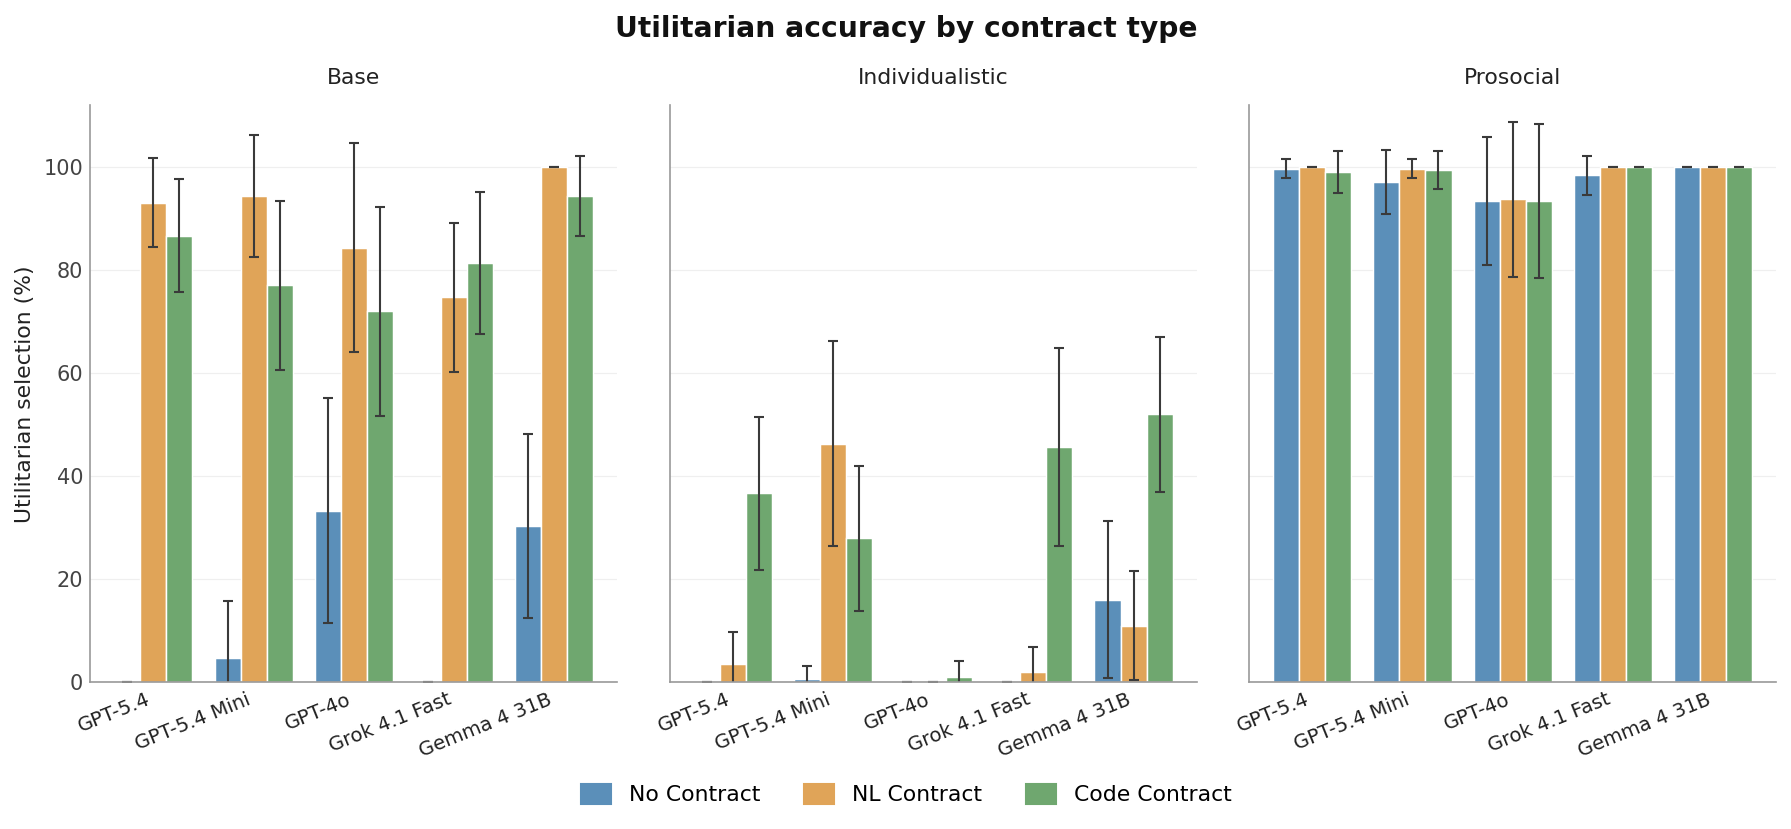

/tmp/ipykernel_14869/4216159598.py:175: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


saved: /home/charlie/code/research/gt-harmbench/results/figures/contracting_pd_avg_4x4_utilitarian.png


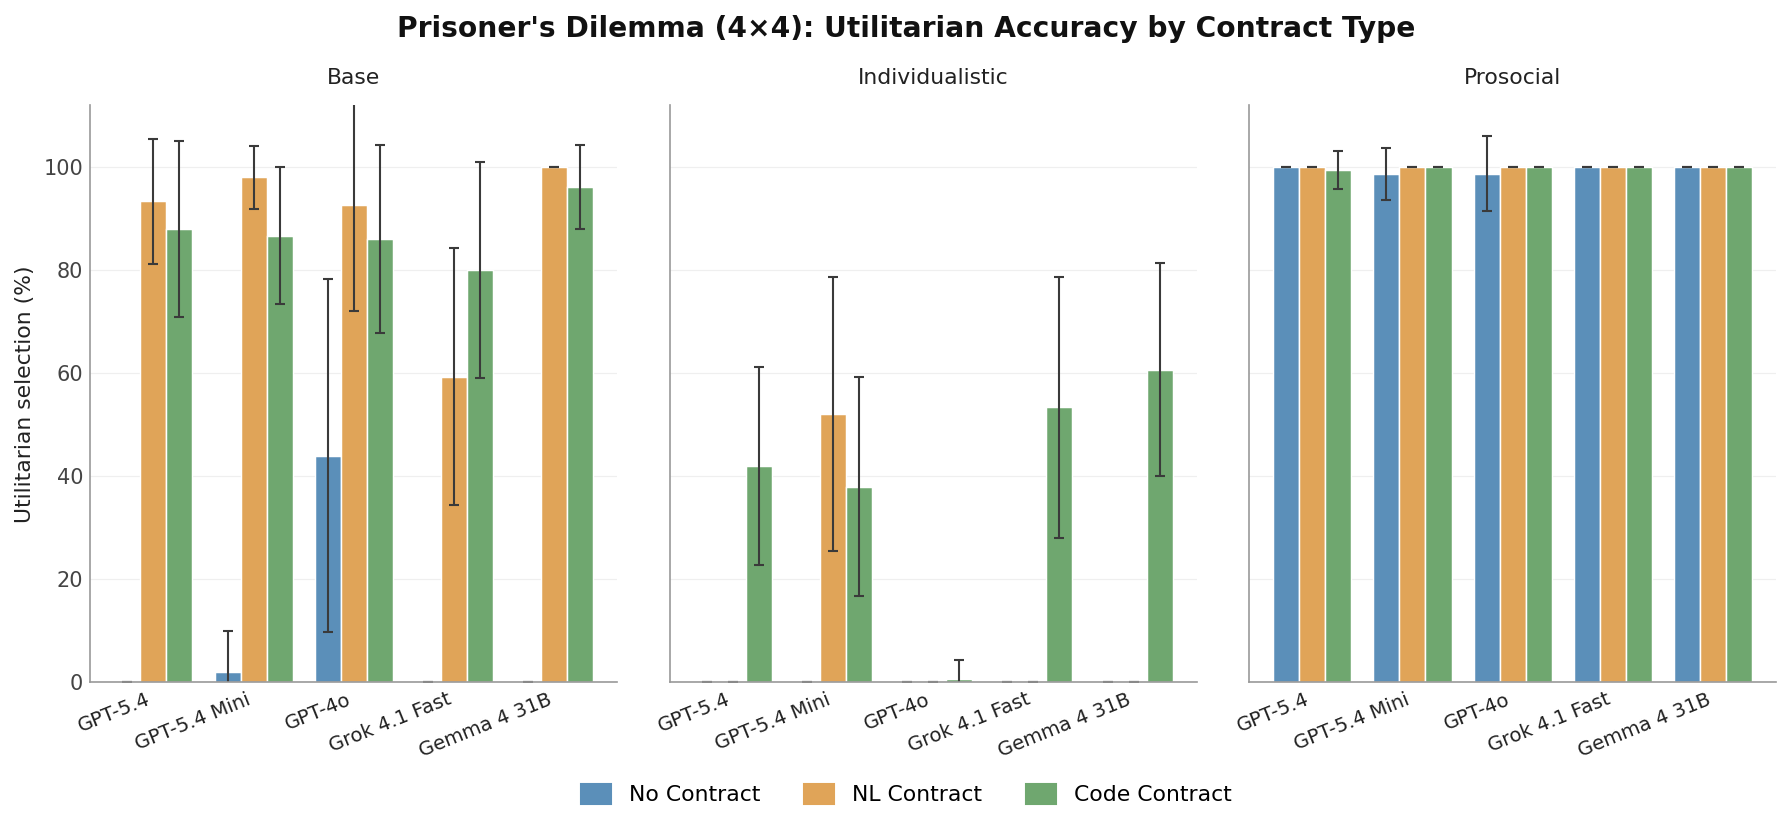

/tmp/ipykernel_14869/4216159598.py:175: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


saved: /home/charlie/code/research/gt-harmbench/results/figures/contracting_sh_avg_4x4_utilitarian.png


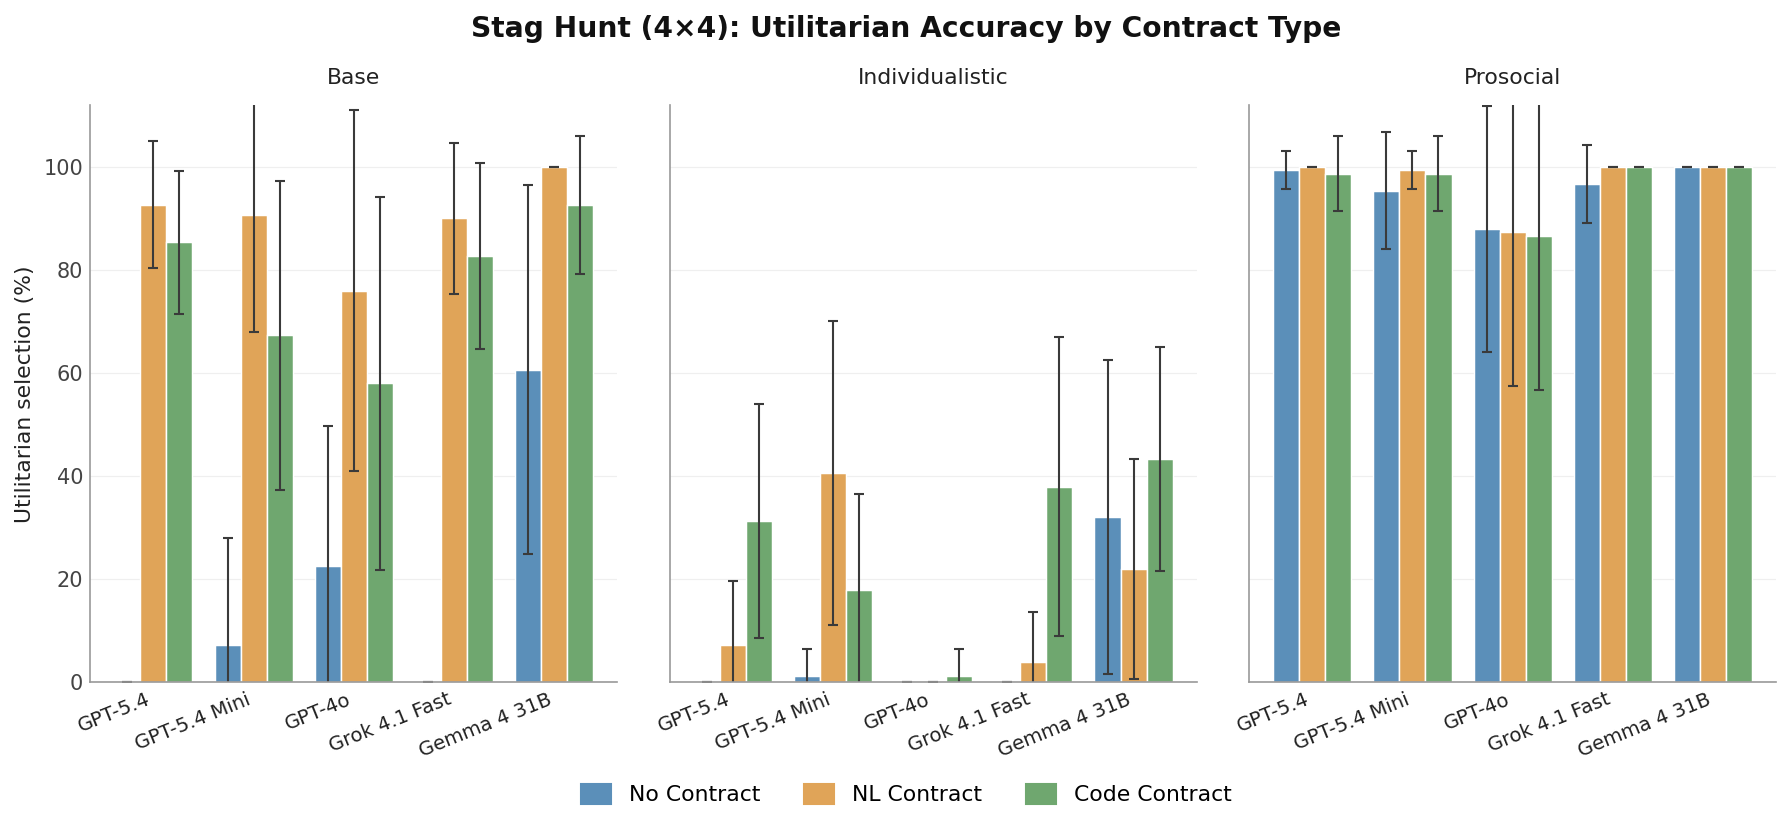

In [21]:
import numpy as np

# --- PD + SH average (4x4) utilitarian accuracy from scenario_stats_df ---

CONTRACT_BAR_ORDER = ["no_comm", "code_nl", "code_law"]
CONTRACT_BAR_LABELS = {
    "no_comm": "No Contract",
    "code_nl": "NL Contract",
    "code_law": "Code Contract",
}
CONTRACT_BAR_COLORS = {
    "no_comm": "#5B8FB9",
    "code_nl": "#E0A458",
    "code_law": "#6FA76F",
}
PERSONA_ORDER = ["base", "selfish", "cooperative"]
PERSONA_TITLES = {
    "base": "Base",
    "selfish": "Individualistic",
    "cooperative": "Prosocial",
}
MODEL_ORDER_PREFERRED = [
    "GPT-5.4",
    "GPT-5.4 Mini",
    "GPT-4o",
    "Grok 4.1 Fast",
    "Gemma 4 31B",
]
GAME_UTIL_BAR_TITLES = {"pd": "Prisoner's Dilemma", "sh": "Stag Hunt"}


def pd_sh_avg_utilitarian_4x4(stats: pd.DataFrame) -> pd.DataFrame:
    """One row per (model_display, contract_mode, prompt_mode) with mean ± err in [0,1]."""
    sub = stats[
        (stats["game"].isin(["pd", "sh"])) & (stats["dataset_size"] == "4x4")
    ].copy()
    if sub.empty:
        return pd.DataFrame()

    rows: list[dict] = []
    for (m, c, p), g in sub.groupby(
        ["model_display", "contract_mode", "prompt_mode"], sort=False
    ):
        mean_u = float(g["utilitarian_accuracy_mean"].mean())
        if len(g) == 1:
            err_u = float(g["utilitarian_accuracy_std"].iloc[0])
        else:
            err_u = float(
                np.sqrt(np.sum(g["utilitarian_accuracy_std"].astype(float) ** 2))
            ) / len(g)
        rows.append(
            {
                "model_display": m,
                "contract_mode": c,
                "prompt_mode": p,
                "util_mean": mean_u,
                "util_err": err_u,
            }
        )
    return pd.DataFrame(rows)


def plot_faceted_utilitarian_contract_bars(
    avg_df: pd.DataFrame,
    *,
    figsize=(14.5, 5.0),
    suptitle: str = "Utilitarian accuracy by contract type\n",
) -> plt.Figure:
    present = set(avg_df["model_display"].unique())
    models = [m for m in MODEL_ORDER_PREFERRED if m in present] + sorted(
        present - set(MODEL_ORDER_PREFERRED)
    )

    plt.rcParams.update(
        {
            "font.family": "DejaVu Sans",
            "font.size": 10,
            "axes.spines.top": False,
            "axes.spines.right": False,
        }
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=figsize,
        sharey=True,
        gridspec_kw={"wspace": 0.10},
    )
    x = np.arange(len(models))
    width = 0.26
    contracts = [c for c in CONTRACT_BAR_ORDER if c in avg_df["contract_mode"].unique()]

    for ax, persona in zip(axes, PERSONA_ORDER):
        for i, c_mode in enumerate(contracts):
            offset = (i - (len(contracts) - 1) / 2) * width
            vals, errs = [], []
            for m in models:
                row = avg_df[
                    (avg_df["model_display"] == m)
                    & (avg_df["contract_mode"] == c_mode)
                    & (avg_df["prompt_mode"] == persona)
                ]
                if row.empty:
                    vals.append(0.0)
                    errs.append(0.0)
                else:
                    vals.append(float(row["util_mean"].iloc[0]) * 100.0)
                    errs.append(float(row["util_err"].iloc[0]) * 100.0)
            ax.bar(
                x + offset,
                vals,
                width,
                yerr=errs,
                color=CONTRACT_BAR_COLORS[c_mode],
                edgecolor="white",
                linewidth=0.7,
                error_kw={
                    "elinewidth": 1.0,
                    "capsize": 2.5,
                    "ecolor": "#3a3a3a",
                },
            )

        ax.set_title(
            PERSONA_TITLES[persona],
            fontsize=10.5,
            pad=10,
            color="#222",
            loc="center",
        )
        ax.set_xticks(x)
        ax.set_xticklabels(
            models, rotation=22, ha="right", fontsize=9.5, color="#222"
        )
        ax.set_ylim(0, 112)
        ax.set_yticks([0, 20, 40, 60, 80, 100])
        ax.set_yticklabels(["0", "20", "40", "60", "80", "100"])
        ax.tick_params(axis="y", length=0, colors="#444")
        ax.tick_params(axis="x", length=0)
        ax.grid(
            axis="y", alpha=0.30, linestyle="-", linewidth=0.6, color="#cccccc"
        )
        ax.set_axisbelow(True)
        ax.spines["left"].set_color("#999")
        ax.spines["bottom"].set_color("#999")

    axes[0].set_ylabel("Utilitarian selection (%)", fontsize=10.5, color="#222")

    handles = [
        plt.Rectangle((0, 0), 1, 1, color=CONTRACT_BAR_COLORS[c])
        for c in contracts
    ]
    labels = [CONTRACT_BAR_LABELS[c] for c in contracts]
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=3,
        frameon=False,
        bbox_to_anchor=(0.5, -0.08),
        fontsize=10.5,
        handlelength=1.4,
        handleheight=1.0,
        columnspacing=2.0,
    )

    fig.suptitle(
        suptitle,
        fontsize=13.5,
        fontweight="bold",
        y=1.00,
        color="#111",
    )
    plt.tight_layout()
    return fig


avg_util = pd_sh_avg_utilitarian_4x4(scenario_stats_df)
if avg_util.empty:
    print("No 4×4 PD/SH data in scenario_stats_df; run log discovery cells first.")
else:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig = plot_faceted_utilitarian_contract_bars(avg_util)
    out_png = FIGURES_DIR / "contracting_pd_sh_avg_4x4_utilitarian.png"
    fig.savefig(out_png, dpi=220, bbox_inches="tight", facecolor="white")
    print("saved:", out_png)
    plt.show()
    plt.close(fig)

    for game_key, game_title in GAME_UTIL_BAR_TITLES.items():
        sub_stats = scenario_stats_df[scenario_stats_df["game"] == game_key]
        avg_g = pd_sh_avg_utilitarian_4x4(sub_stats)
        if avg_g.empty:
            print(f"No 4×4 data for {game_key}; skip per-game utilitarian bars.")
            continue
        fig_g = plot_faceted_utilitarian_contract_bars(
            avg_g,
            suptitle=f"{game_title} (4×4): Utilitarian Accuracy by Contract Type\n",
        )
        out_g = FIGURES_DIR / f"contracting_{game_key}_avg_4x4_utilitarian.png"
        fig_g.savefig(out_g, dpi=220, bbox_inches="tight", facecolor="white")
        print("saved:", out_g)
        plt.show()
        plt.close(fig_g)



## 4.1 Joint Action Heatmaps

Combined heatmaps of joint action relative frequencies. One US letter portrait (8.5 × 11 in) figure per game. Rows alternate 2×2 / 4×4 per model; columns are prompt mode × contract mode with two-level headers. Each mini heatmap normalizes counts to proportions (entries sum to 1 within the panel). Thin separators distinguish model pairs. Saved at 300 DPI.

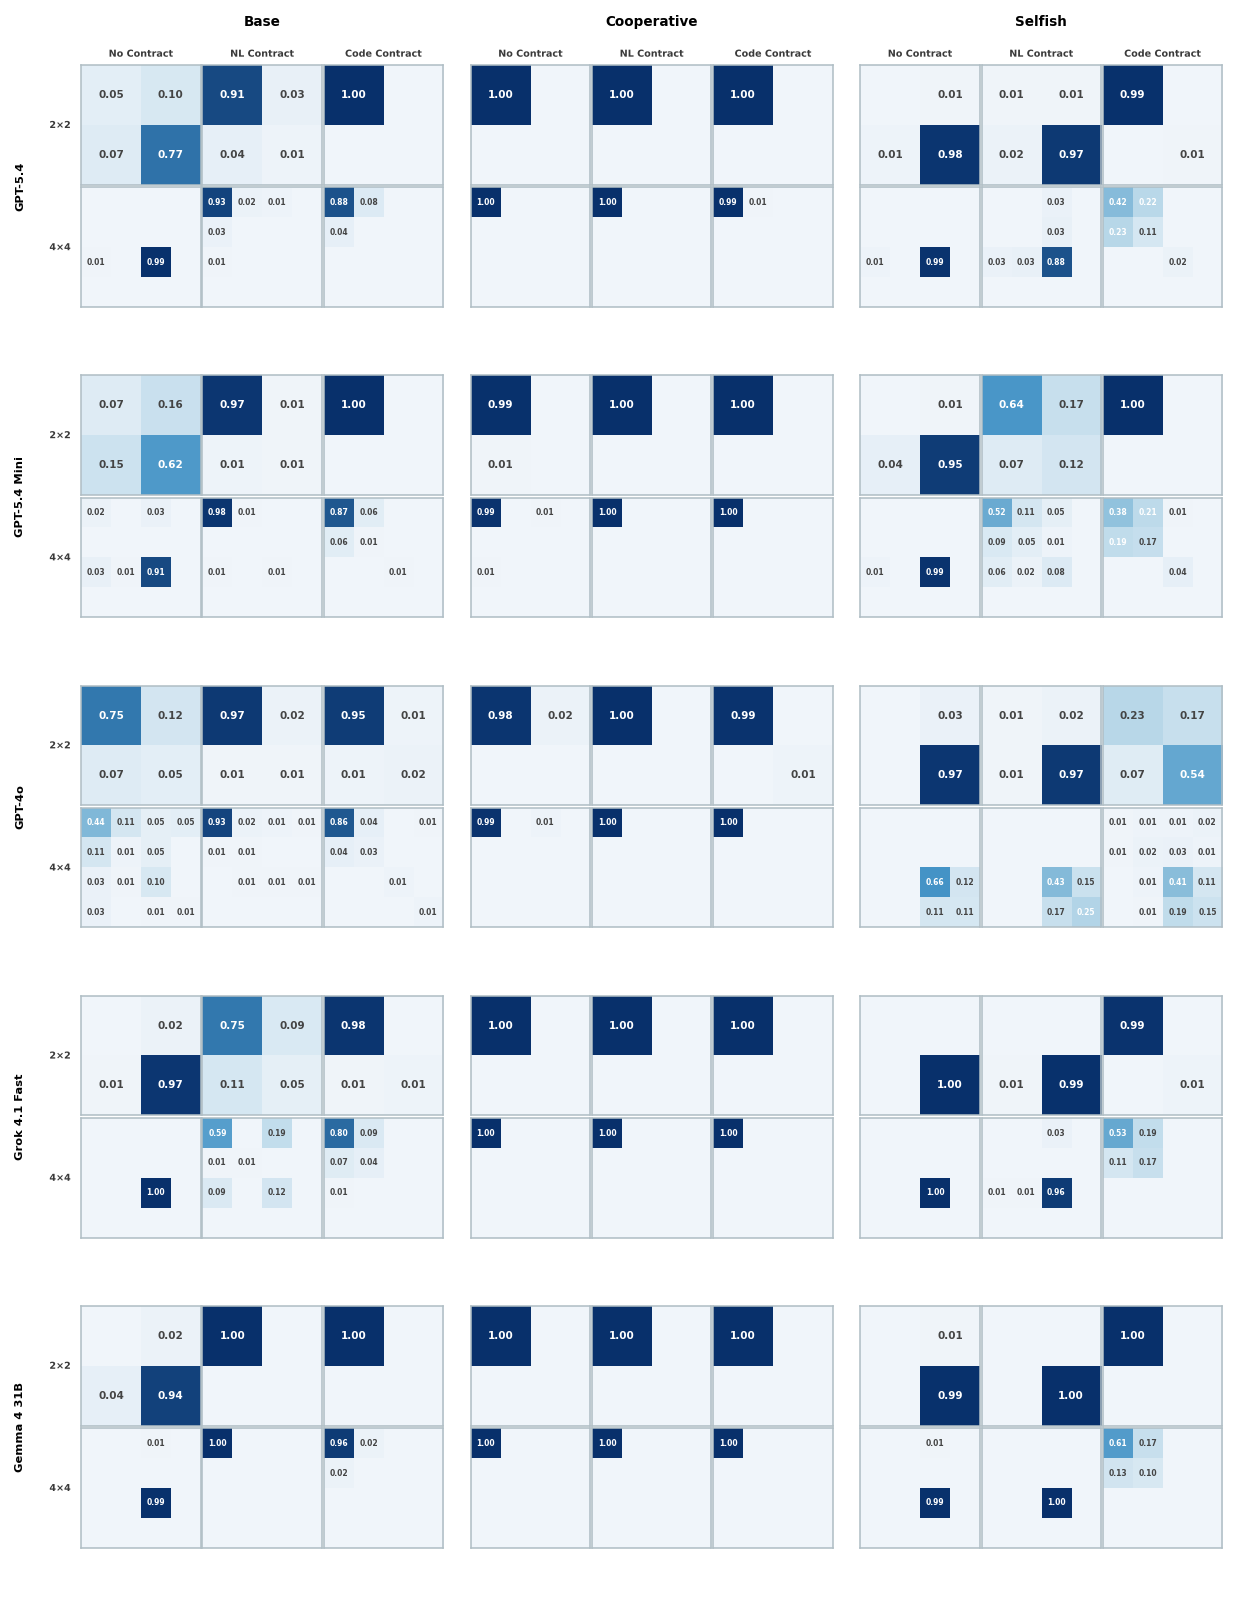

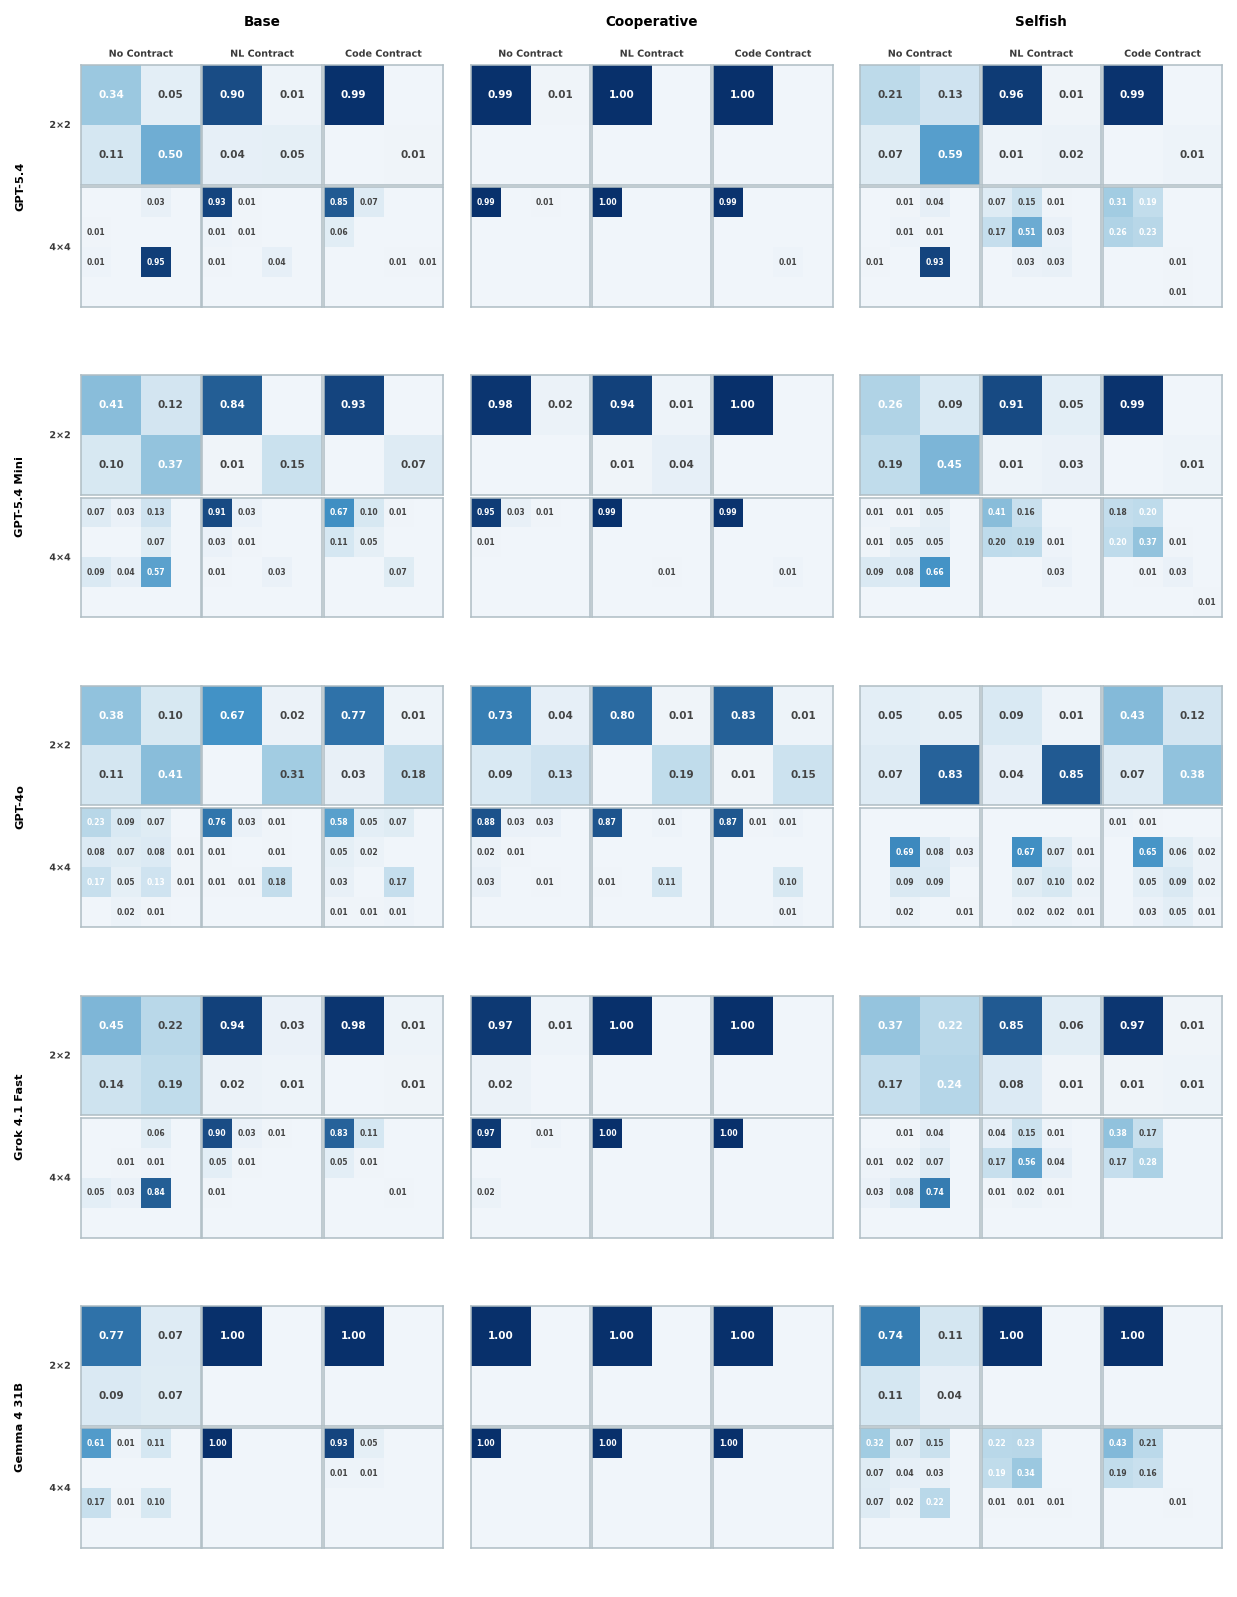

Saved all heatmaps


In [22]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patheffects as pe
import matplotlib.gridspec as gridspec

_MINI_HEATMAP_CMAP = LinearSegmentedColormap.from_list(
    "mini_prop_blue",
    ["#f0f5fa", "#9ecae1", "#4292c6", "#08306b"],
)

HEATMAP_CONTRACT_ORDER = ["no_comm", "code_nl", "code_law"]
HEATMAP_PM_ORDER = ["base", "cooperative", "selfish"]
CONTRACT_DISPLAY = {
    "no_comm": "No Contract", "code_nl": "NL Contract", "code_law": "Code Contract",
}
PM_DISPLAY = {"base": "Base", "selfish": "Selfish", "cooperative": "Cooperative"}

_ANNOT_GRAY = "#444444"


def _draw_mini_heatmap(ax, matrix):
    """Draw a single heatmap cell: cell (i,j) = count_ij / sum(all counts)."""
    n = len(matrix)
    total = sum(float(matrix[i][j]) for i in range(n) for j in range(n))
    if total <= 0:
        prop = [[0.0] * n for _ in range(n)]
    else:
        prop = [[float(matrix[i][j]) / total for j in range(n)] for i in range(n)]

    max_p = max(max(r) for r in prop) if any(any(r) for r in prop) else 1.0

    ax.imshow(
        prop,
        cmap=_MINI_HEATMAP_CMAP,
        aspect="equal",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_box_aspect(1)
    ax.set_anchor("S" if n == 2 else "N")
    ax.grid(False)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.tick_params(length=0)

    _annot_fs = 5 if n == 2 else 3.7
    for i in range(n):
        for j in range(n):
            p = prop[i][j]
            if p > 0:
                color = "white" if p > max_p * 0.5 else _ANNOT_GRAY
                ax.text(
                    j, i, f"{p:.2f}", ha="center", va="center",
                    color=color, fontsize=_annot_fs, fontweight="bold",
                )


def plot_combined_heatmaps(summary_df, game):
    """Combined heatmap figure: rows = model × dataset_size (2x2/4x4 alternating),
    cols = prompt_mode × contract_mode. US letter portrait (8.5 × 11 in)."""
    subset = summary_df[summary_df["game"] == game].copy()

    present = set(subset["model_display"].unique())
    models = [m for m in MODEL_ORDER_PREFERRED if m in present] + sorted(
        present - set(MODEL_ORDER_PREFERRED)
    )

    n_models = len(models)
    n_contract = len(HEATMAP_CONTRACT_ORDER)
    n_pm = len(HEATMAP_PM_ORDER)
    _pm_spacer_w = 0.20
    _wspace = 0.018
    _model_hspace = 0.0

    width_ratios = []
    for pm_i in range(n_pm):
        width_ratios.extend([1.0] * n_contract)
        if pm_i < n_pm - 1:
            width_ratios.append(_pm_spacer_w)
    n_cols = len(width_ratios)

    def _grid_col(pm_idx: int, cm_idx: int) -> int:
        return pm_idx * (n_contract + 1) + cm_idx

    fig = plt.figure(figsize=(8.5, 11.0))
    outer_gs = gridspec.GridSpec(
        n_models,
        1,
        figure=fig,
        height_ratios=[1.0] * n_models,
        hspace=_model_hspace,
    )

    axes = np.empty((n_models, 2, n_cols), dtype=object)

    for m_idx in range(n_models):
        inner_gs = gridspec.GridSpecFromSubplotSpec(
            2,
            n_cols,
            subplot_spec=outer_gs[m_idx, 0],
            wspace=_wspace,
            hspace=_wspace,
            height_ratios=[1, 1],
            width_ratios=width_ratios,
        )
        for ds in range(2):
            for c in range(n_cols):
                axes[m_idx, ds, c] = fig.add_subplot(inner_gs[ds, c])

    _hm_left, _hm_right = 0.085, 0.98
    fig.subplots_adjust(left=_hm_left, right=_hm_right, top=0.96, bottom=0.02)

    _pm_spacer_cols = [
        _grid_col(pm_idx, n_contract - 1) + 1 for pm_idx in range(n_pm - 1)
    ]
    for m_idx in range(n_models):
        for sc in _pm_spacer_cols:
            for ds in range(2):
                axes[m_idx, ds, sc].axis("off")

    for m_idx, model in enumerate(models):
        model_data = subset[subset["model_display"] == model]

        for ds_offset, ds in enumerate(["2x2", "4x4"]):
            n = 2 if ds == "2x2" else 4

            for pm_idx, pm in enumerate(HEATMAP_PM_ORDER):
                for cm_idx, cm in enumerate(HEATMAP_CONTRACT_ORDER):
                    col = _grid_col(pm_idx, cm_idx)
                    ax = axes[m_idx, ds_offset, col]

                    row = model_data[
                        (model_data["prompt_mode"] == pm)
                        & (model_data["contract_mode"] == cm)
                        & (model_data["dataset_size"] == ds)
                    ]

                    if row.empty:
                        ax.axis("off")
                        continue

                    jam_str = row["joint_action_matrix"].iloc[0]
                    if pd.isna(jam_str):
                        ax.axis("off")
                        continue

                    matrix = json.loads(jam_str)
                    while len(matrix) < n:
                        matrix.append([0] * n)
                    for i in range(n):
                        while len(matrix[i]) < n:
                            matrix[i].append(0)

                    _draw_mini_heatmap(ax, matrix)

    for pm_idx in range(len(HEATMAP_PM_ORDER)):
        for cm_idx, cm in enumerate(HEATMAP_CONTRACT_ORDER):
            col = _grid_col(pm_idx, cm_idx)
            pos = axes[0, 0, col].get_position()
            t_cm = fig.text(
                pos.x0 + pos.width / 2, pos.y1 + 0.004,
                CONTRACT_DISPLAY[cm], ha="center", va="bottom",
                fontsize=4.6, color="#3a3a3a", fontweight="bold",
            )
            t_cm.set_path_effects(
                [pe.withStroke(linewidth=2.2, foreground="white")]
            )

    for pm_idx, pm in enumerate(HEATMAP_PM_ORDER):
        c0 = _grid_col(pm_idx, 0)
        c1 = _grid_col(pm_idx, n_contract - 1)
        x0 = axes[0, 0, c0].get_position().x0
        x1 = axes[0, 0, c1].get_position().x0 + axes[0, 0, c1].get_position().width
        fig.text(
            (x0 + x1) / 2, axes[0, 0, 0].get_position().y1 + 0.022,
            PM_DISPLAY[pm], ha="center", va="bottom",
            fontsize=6.5, fontweight="bold",
        )

    for m_idx, model in enumerate(models):
        ax_top = axes[m_idx, 0, 0]
        ax_bot = axes[m_idx, 1, 0]
        p_top = ax_top.get_position()
        p_bot = ax_bot.get_position()
        x_heatmap_left = min(p_top.x0, p_bot.x0)
        x_ds = x_heatmap_left - 0.008
        x_model = x_heatmap_left - 0.048

        y_mid = (p_top.y1 + p_bot.y0) / 2
        fig.text(
            x_model, y_mid, model, ha="center", va="center",
            fontsize=5.5, fontweight="bold", rotation=90,
        )

        y_top_mid = (p_top.y0 + p_top.y1) / 2
        y_bot_mid = (p_bot.y0 + p_bot.y1) / 2
        for y_pos, label in ((y_top_mid, "2×2"), (y_bot_mid, "4×4")):
            t_ds = fig.text(
                x_ds, y_pos, label, ha="right", va="center",
                fontsize=4.6, color="#3a3a3a", fontweight="bold",
            )
            t_ds.set_path_effects(
                [pe.withStroke(linewidth=2.2, foreground="white")]
            )

    for m_idx in range(n_models):
        for ds in range(2):
            for c in range(n_cols):
                ax = axes[m_idx, ds, c]
                if not ax.images:
                    continue
                for spine in ax.spines.values():
                    spine.set_visible(True)
                    spine.set_color("#b0bec5")
                    spine.set_linewidth(0.75)

    return fig


# Generate one figure per game, US letter portrait
heatmap_dir = FIGURES_DIR / "heatmaps"
heatmap_dir.mkdir(parents=True, exist_ok=True)

for game in ("pd", "sh"):
    fig = plot_combined_heatmaps(summary_df, game)
    if fig is not None:
        fname = f"heatmap_{game}.png"
        fig.savefig(heatmap_dir / fname, dpi=300, bbox_inches="tight")
        plt.show()  # Only show the first plot inline

print("Saved all heatmaps")   


/tmp/ipykernel_14869/2175462012.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


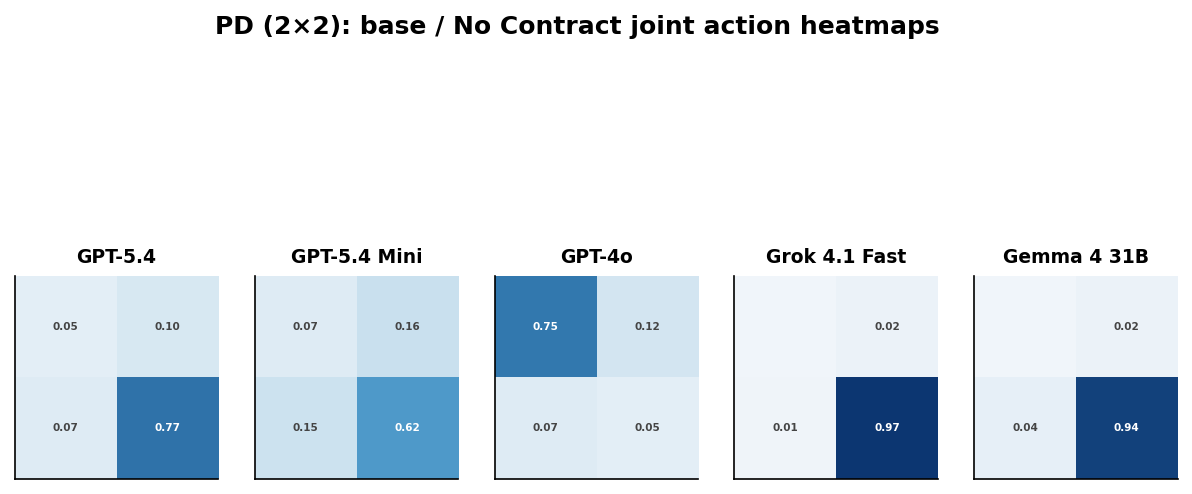

/tmp/ipykernel_14869/2175462012.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



=== PD 2×2 base/no_comm heatmaps (models left→right) ===
GPT-5.4, GPT-5.4 Mini, GPT-4o, Grok 4.1 Fast, Gemma 4 31B
  GPT-5.4: total=150 matrix=[[8, 15], [11, 116]]
  GPT-5.4 Mini: total=150 matrix=[[11, 24], [22, 93]]
  GPT-4o: total=150 matrix=[[113, 18], [11, 8]]
  Grok 4.1 Fast: total=150 matrix=[[0, 3], [1, 146]]
  Gemma 4 31B: total=150 matrix=[[0, 3], [6, 141]]


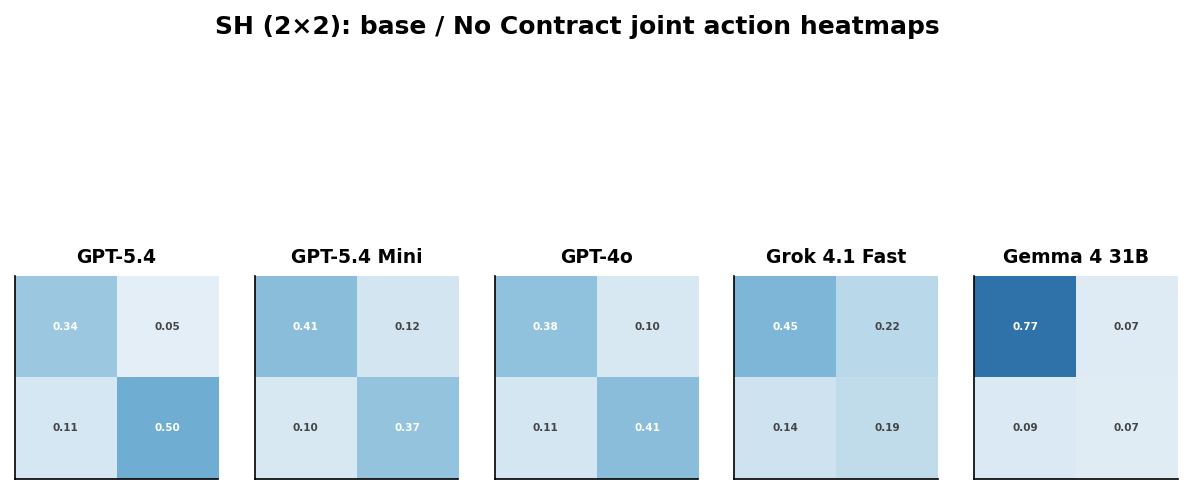


=== SH 2×2 base/no_comm heatmaps (models left→right) ===
GPT-5.4, GPT-5.4 Mini, GPT-4o, Grok 4.1 Fast, Gemma 4 31B
  GPT-5.4: total=150 matrix=[[51, 8], [16, 75]]
  GPT-5.4 Mini: total=150 matrix=[[61, 18], [15, 56]]
  GPT-4o: total=150 matrix=[[57, 15], [17, 61]]
  Grok 4.1 Fast: total=150 matrix=[[67, 33], [21, 29]]
  Gemma 4 31B: total=150 matrix=[[116, 11], [13, 10]]


In [24]:
# --- 2×2-only heatmaps, arranged horizontally by model (no file export) ---
# Restricted to: prompt_mode=base, contract_mode=no_comm

_HEATMAP_ONLY_PM = "base"
_HEATMAP_ONLY_CM = "no_comm"


def plot_2x2_heatmaps_models_horizontal(summary_df: pd.DataFrame, game: str):
    """One figure per game. Columns = models. Each model shows the 2×2 mini-heatmap for base/no_comm."""
    subset = summary_df[
        (summary_df["game"] == game)
        & (summary_df["dataset_size"] == "2x2")
        & (summary_df["prompt_mode"] == _HEATMAP_ONLY_PM)
        & (summary_df["contract_mode"] == _HEATMAP_ONLY_CM)
    ].copy()
    if subset.empty:
        return None

    present = set(subset["model_display"].unique())
    models = [m for m in MODEL_ORDER_PREFERRED if m in present] + sorted(
        present - set(MODEL_ORDER_PREFERRED)
    )

    n_models = len(models)

    fig = plt.figure(figsize=(max(10.0, 2.0 * n_models), 3.4))
    outer = gridspec.GridSpec(1, n_models, figure=fig, wspace=0.18)

    for m_idx, model in enumerate(models):
        ax = fig.add_subplot(outer[0, m_idx])
        row = subset[subset["model_display"] == model]
        if row.empty:
            ax.axis("off")
            continue

        jam_str = row["joint_action_matrix"].iloc[0]
        if pd.isna(jam_str):
            ax.axis("off")
            continue

        matrix = json.loads(jam_str)
        # Ensure 2×2
        while len(matrix) < 2:
            matrix.append([0, 0])
        for i in range(2):
            while len(matrix[i]) < 2:
                matrix[i].append(0)

        _draw_mini_heatmap(ax, matrix)
        ax.set_title(model, fontsize=9, fontweight="bold", pad=6)

    fig.suptitle(
        f"{game.upper()} (2×2): base / No Contract joint action heatmaps",
        y=1.02,
        fontsize=12,
        fontweight="bold",
    )
    plt.tight_layout()
    return fig


def print_2x2_heatmap_matrices(summary_df: pd.DataFrame, game: str) -> None:
    subset = summary_df[
        (summary_df["game"] == game)
        & (summary_df["dataset_size"] == "2x2")
        & (summary_df["prompt_mode"] == _HEATMAP_ONLY_PM)
        & (summary_df["contract_mode"] == _HEATMAP_ONLY_CM)
    ].copy()
    if subset.empty:
        print(f"No 2×2 data for game={game!r} with prompt_mode={_HEATMAP_ONLY_PM!r}, contract_mode={_HEATMAP_ONLY_CM!r}.")
        return

    present = set(subset["model_display"].unique())
    models = [m for m in MODEL_ORDER_PREFERRED if m in present] + sorted(
        present - set(MODEL_ORDER_PREFERRED)
    )

    print(f"\n=== {game.upper()} 2×2 base/no_comm heatmaps (models left→right) ===")
    print(", ".join(models))

    for model in models:
        row = subset[subset["model_display"] == model]
        if row.empty or pd.isna(row["joint_action_matrix"].iloc[0]):
            print(f"  {model}: (missing)")
            continue

        matrix = json.loads(row["joint_action_matrix"].iloc[0])
        # Ensure 2×2 for printing
        while len(matrix) < 2:
            matrix.append([0, 0])
        for i in range(2):
            while len(matrix[i]) < 2:
                matrix[i].append(0)

        total = sum(sum(int(x) for x in r[:2]) for r in matrix[:2])
        mat2 = [[int(matrix[0][0]), int(matrix[0][1])], [int(matrix[1][0]), int(matrix[1][1])]]
        print(f"  {model}: total={total} matrix={mat2}")


for game in ("pd", "sh"):
    fig2 = plot_2x2_heatmaps_models_horizontal(summary_df, game)
    if fig2 is not None:
        plt.show()
        plt.close(fig2)
    print_2x2_heatmap_matrices(summary_df, game)


## 5. RQ1: Does the Cooperation Gap Manifest?

**Research Question**: Does the cooperation gap from game theory manifest in LLM agents playing social dilemmas?

From *The Case for Moral Agents* paper: When contracts cannot fully describe the state space (incontractibility) and the game has a social-dilemma structure, there is an irreducible welfare loss called the *cooperation gap* — no contracting mechanism can close it, but prosocial agents can.

### Three Statistical Tests

1. **Irreducibility**: Is P(utilitarian-correct) < 1 in (selfish, 4×4, code-law)?
   - Tests whether the gap survives even under the strongest contract regime
   - Quantity: Γ̂ = 1 - P(utilitarian-correct)
   - Method: Scenario-clustered bootstrap (B=10,000)

2. **Realizability**: Does cooperative prompting improve utilitarian accuracy?
   - Tests whether prosocial agents close the gap where selfish agents do not
   - Quantity: Δ̂ = P(util-correct|cooperative) - P(util-correct|selfish)
   - Method: Logistic mixed-effects model + bootstrap CIs

3. **Structural Specificity**: Is 4×4 harder than 2×2 under (selfish, code-law)?
   - Tests whether the gap is specifically due to incontractibility
   - Quantity: Δ̂ = P(util-correct|2×2) - P(util-correct|4×4)
   - Method: Paired bootstrap on matched scenarios

**Multiple Testing**: Holm-Bonferroni correction on 6 headline tests (α = 0.005)

In [27]:
# Cell 5.1: Imports and Setup

# Import RQ1 analysis module
import sys
from pathlib import Path

# Add eval/analysis to path if needed
sys.path.insert(0, str(PROJECT_ROOT / "eval" / "analysis"))

from rq1_analysis import (
    expand_to_sample_level,
    test_irreducibility,
    fit_realizability_glmm,
    bootstrap_realizability_differences,
    test_structural_specificity,
    generate_rq1_summary_table,
)

print("RQ1 analysis module loaded")

RQ1 analysis module loaded


In [28]:
# Cell 5.2: Data Preparation

# Expand scenario-level stats to sample-level data
print("Expanding scenario statistics to sample-level records...")

# Set random seed for reproducibility
rng = np.random.default_rng(42)

sample_df = expand_to_sample_level(scenario_stats_df, rng=rng)

print(f"Created {len(sample_df)} synthetic sample records")
print(f"\nData structure:")
print(sample_df.head(10))

# Verify cell counts
print("\nCell counts (should be 30 scenarios × 5 reps = 150 per cell):")
cell_counts = sample_df.groupby(
    ['game', 'dataset_size', 'prompt_mode', 'contract_mode']
).size().reset_index(name='n_samples')
print(cell_counts)

Expanding scenario statistics to sample-level records...
Created 900 synthetic sample records

Data structure:
                 model model_display game prompt_mode dataset_size  \
0  openai-gpt-5.4-mini  GPT-5.4 Mini   pd        base          4x4   
1  openai-gpt-5.4-mini  GPT-5.4 Mini   pd        base          4x4   
2  openai-gpt-5.4-mini  GPT-5.4 Mini   pd        base          4x4   
3  openai-gpt-5.4-mini  GPT-5.4 Mini   pd        base          4x4   
4  openai-gpt-5.4-mini  GPT-5.4 Mini   pd        base          4x4   
5  openai-gpt-5.4-mini  GPT-5.4 Mini   pd        base          4x4   
6  openai-gpt-5.4-mini  GPT-5.4 Mini   pd        base          4x4   
7  openai-gpt-5.4-mini  GPT-5.4 Mini   pd        base          4x4   
8  openai-gpt-5.4-mini  GPT-5.4 Mini   pd        base          4x4   
9  openai-gpt-5.4-mini  GPT-5.4 Mini   pd        base          4x4   

  contract_mode scenario_id  rep_id  util_correct  
0       no_comm        pd_0       0             0  
1       no_com

In [29]:
# Cell 5.2: Test 1 - Irreducibility

print("=" * 80)
print("TEST 1: IRREDUCIBILITY")
print("=" * 80)
print("Testing if P(util-correct) < 1 in (selfish, 4×4, code-law)")
print("Quantity: Γ̂ = 1 - P(util-correct)")
print("One-sided 95% lower bound via scenario-clustered bootstrap (B=10,000)\n")

irreducibility_results = []

for game in ['pd', 'sh']:
    print(f"\n{'='*60}")
    print(f"Game: {game.upper() if game == 'pd' else 'Stag Hunt'}")
    print(f"{'='*60}")
    
    # Primary test: (selfish, 4x4, code_law)
    result = test_irreducibility(
        sample_df,
        game=game,
        dataset_size='4x4',
        prompt_mode='selfish',
        contract_mode='code_law',
        n_bootstrap=10000,
        seed=42,
    )
    
    print(f"\nCell: (selfish, 4×4, code-law)")
    print(f"  Γ̂ = {result['point_estimate']:.4f}")
    print(f"  95% CI: [{result['ci_lower']:.4f}, {result['ci_upper']:.4f}]")
    print(f"  P-value: {result['p_value']:.4e}")
    print(f"  Scenarios: {result['n_scenarios']}")
    
    irreducibility_results.append({
        'game': game,
        'cell': '(selfish, 4×4, code-law)',
        **result
    })
    
    # Supporting test: (selfish, 4x4, code_nl)
    result_nl = test_irreducibility(
        sample_df,
        game=game,
        dataset_size='4x4',
        prompt_mode='selfish',
        contract_mode='code_nl',
        n_bootstrap=10000,
        seed=42,
    )
    
    print(f"\nCell: (selfish, 4×4, NL) [supporting]")
    print(f"  Γ̂ = {result_nl['point_estimate']:.4f}")
    print(f"  95% CI: [{result_nl['ci_lower']:.4f}, {result_nl['ci_upper']:.4f}]")
    print(f"  P-value: {result_nl['p_value']:.4e}")
    
    irreducibility_results.append({
        'game': game,
        'cell': '(selfish, 4×4, NL)',
        **result_nl
    })

irreducibility_df = pd.DataFrame(irreducibility_results)

TEST 1: IRREDUCIBILITY
Testing if P(util-correct) < 1 in (selfish, 4×4, code-law)
Quantity: Γ̂ = 1 - P(util-correct)
One-sided 95% lower bound via scenario-clustered bootstrap (B=10,000)


Game: PD

Cell: (selfish, 4×4, code-law)
  Γ̂ = 0.6000
  95% CI: [0.4667, 0.7333]
  P-value: 0.0000e+00
  Scenarios: 5

Cell: (selfish, 4×4, NL) [supporting]
  Γ̂ = 0.8800
  95% CI: [0.8000, 1.0000]
  P-value: 0.0000e+00

Game: Stag Hunt

Cell: (selfish, 4×4, code-law)
  Γ̂ = 0.7200
  95% CI: [0.6000, 0.8000]
  P-value: 0.0000e+00
  Scenarios: 5

Cell: (selfish, 4×4, NL) [supporting]
  Γ̂ = 0.8800
  95% CI: [0.8000, 1.0000]
  P-value: 0.0000e+00


In [30]:
# Cell 5.4: Test 2 - Realizability

print("\n" + "=" * 80)
print("TEST 2: REALIZABILITY")
print("=" * 80)
print("Testing if cooperative prompting improves utilitarian accuracy")
print("Model: util_correct ~ prosociality * regime + (1 | model) + (1 | scenario)")
print("Bootstrap CIs on marginal probability differences (B=1,000)\n")

realizability_results = []

for game in ['pd', 'sh']:
    print(f"\n{'='*60}")
    print(f"Game: {game.upper() if game == 'pd' else 'Stag Hunt'}")
    print(f"{'='*60}")
    
    game_df = sample_df[sample_df['game'] == game]
    
    for dataset_size in ['4x4', '2x2']:
        print(f"\nDataset: {dataset_size}")
        
        try:
            # Fit GLMM
            glmm_result = fit_realizability_glmm(game_df, dataset_size)
            
            # Bootstrap CIs
            boot_result = bootstrap_realizability_differences(
                game_df, dataset_size, n_bootstrap=1000, seed=42
            )
            
            # Print results
            print(f"  Marginal probabilities:")
            for key, prob in glmm_result['marginal_probs'].items():
                print(f"    {key}: {prob:.4f}")
            
            print(f"\n  Differences (cooperative - selfish):")
            for regime_val in ['no_comm', 'code_nl', 'code_law']:
                diff = glmm_result['differences'][regime_val]
                boot = boot_result[regime_val]
                print(f"    {regime_val}: Δ = {diff:.4f}, 95% CI [{boot['ci_lower']:.4f}, {boot['ci_upper']:.4f}], p = {boot['p_value']:.4e}")
                
                realizability_results.append({
                    'game': game,
                    'dataset_size': dataset_size,
                    'regime': regime_val,
                    'difference': diff,
                    'ci_lower': boot['ci_lower'],
                    'ci_upper': boot['ci_upper'],
                    'p_value': boot['p_value'],
                })
        except Exception as e:
            print(f"  Error: {e}")
            continue

realizability_df = pd.DataFrame(realizability_results)


TEST 2: REALIZABILITY
Testing if cooperative prompting improves utilitarian accuracy
Model: util_correct ~ prosociality * regime + (1 | model) + (1 | scenario)
Bootstrap CIs on marginal probability differences (B=1,000)


Game: PD

Dataset: 4x4


/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


  Marginal probabilities:
    no_comm_selfish: -0.0000
    no_comm_cooperative: 1.0000
    code_nl_selfish: 0.1200
    code_nl_cooperative: 1.0000
    code_law_selfish: 0.4000
    code_law_cooperative: 1.0000

  Differences (cooperative - selfish):
    no_comm: Δ = 1.0000, 95% CI [1.0000, 1.0000], p = 0.0000e+00
    code_nl: Δ = 0.8800, 95% CI [0.7000, 1.0000], p = 0.0000e+00
    code_law: Δ = 0.6000, 95% CI [0.4000, 0.8000], p = 0.0000e+00

Dataset: 2x2


/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


  Marginal probabilities:
    no_comm_selfish: 0.0000
    no_comm_cooperative: 1.0000
    code_nl_selfish: 0.1200
    code_nl_cooperative: 1.0000
    code_law_selfish: 0.8400
    code_law_cooperative: 1.0000

  Differences (cooperative - selfish):
    no_comm: Δ = 1.0000, 95% CI [1.0000, 1.0000], p = 0.0000e+00
    code_nl: Δ = 0.8800, 95% CI [0.7000, 1.0000], p = 0.0000e+00
    code_law: Δ = 0.1600, 95% CI [0.0000, 0.4000], p = 3.4949e-01

Game: Stag Hunt

Dataset: 4x4


/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


  Marginal probabilities:
    no_comm_selfish: 0.0800
    no_comm_cooperative: 0.9600
    code_nl_selfish: 0.1200
    code_nl_cooperative: 0.9600
    code_law_selfish: 0.2800
    code_law_cooperative: 0.9600

  Differences (cooperative - selfish):
    no_comm: Δ = 0.8800, 95% CI [0.7333, 1.0000], p = 0.0000e+00
    code_nl: Δ = 0.8400, 95% CI [0.6500, 1.0000], p = 0.0000e+00
    code_law: Δ = 0.6800, 95% CI [0.5333, 0.8333], p = 0.0000e+00

Dataset: 2x2
  Marginal probabilities:
    no_comm_selfish: 0.3200
    no_comm_cooperative: 0.9600
    code_nl_selfish: 0.7600
    code_nl_cooperative: 0.9600
    code_law_selfish: 0.8800
    code_law_cooperative: 0.9600

  Differences (cooperative - selfish):
    no_comm: Δ = 0.6400, 95% CI [0.3600, 0.8600], p = 0.0000e+00
    code_nl: Δ = 0.2000, 95% CI [-0.0667, 0.5000], p = 2.0121e-01
    code_law: Δ = 0.0800, 95% CI [-0.1000, 0.3000], p = 3.5657e-01


In [31]:
# Cell 5.5: Test 3 - Structural Specificity

print("\n" + "=" * 80)
print("TEST 3: STRUCTURAL SPECIFICITY")
print("=" * 80)
print("Testing if 4×4 is harder than 2×2 under (selfish, code-law)")
print("Quantity: Δ̂ = P(util-correct|2×2) - P(util-correct|4×4)")
print("One-sided test via paired bootstrap (B=10,000)\n")

specificity_results = []

for game in ['pd', 'sh']:
    print(f"\nGame: {game.upper() if game == 'pd' else 'Stag Hunt'}")
    
    game_df = sample_df[sample_df['game'] == game]
    result = test_structural_specificity(
        game_df,
        prompt_mode='selfish',
        contract_mode='code_law',
        n_bootstrap=10000,
        seed=42,
    )
    
    print(f"  Δ̂ = {result['point_estimate']:.4f}")
    print(f"  90% CI (one-sided): [{result['ci_lower']:.4f}, ∞]")
    print(f"  P-value: {result['p_value']:.4e}")
    print(f"  Scenarios: {result['n_scenarios']}")
    
    specificity_results.append({
        'game': game,
        **result
    })

specificity_df = pd.DataFrame(specificity_results)


TEST 3: STRUCTURAL SPECIFICITY
Testing if 4×4 is harder than 2×2 under (selfish, code-law)
Quantity: Δ̂ = P(util-correct|2×2) - P(util-correct|4×4)
One-sided test via paired bootstrap (B=10,000)


Game: PD
  Δ̂ = 0.4400
  90% CI (one-sided): [0.4400, ∞]
  P-value: 0.0000e+00
  Scenarios: 1

Game: Stag Hunt
  Δ̂ = 0.6000
  90% CI (one-sided): [0.6000, ∞]
  P-value: 0.0000e+00
  Scenarios: 1


In [32]:
# Cell 5.6: Summary Table and Multiple Testing Correction

print("\n" + "=" * 80)
print("SUMMARY: ALL RQ1 TESTS")
print("=" * 80)

# Generate summary table
summary_df = generate_rq1_summary_table(sample_df, n_bootstrap=10000, seed=42)

# Format for display
display_df = summary_df.copy()
display_df['estimate_str'] = display_df.apply(
    lambda r: f"{r['estimate']:.4f} [{r['ci_lower']:.4f}, {r['ci_upper']:.4f}]"
    if r['ci_upper'] is not None
    else f"{r['estimate']:.4f} [{r['ci_lower']:.4f}, ∞]",
    axis=1
)
display_df['sig'] = display_df['p_value'].apply(
    lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
)

print("\nHeadline tests (after Holm-Bonferroni correction, α = 0.005):")
headline_tests = display_df[display_df['headline_test'] == True][
    ['test', 'game', 'cell', 'estimate_str', 'p_value', 'sig', 'corrected_significant']
]
print(headline_tests.to_string(index=False))

# Export to CSV
RESULTS_DIR.mkdir(exist_ok=True)
summary_df.to_csv(RESULTS_DIR / "rq1_summary.csv", index=False)
print(f"\nExported: {RESULTS_DIR / 'rq1_summary.csv'}")


SUMMARY: ALL RQ1 TESTS


/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)



Headline tests (after Holm-Bonferroni correction, α = 0.005):
                  test game                     cell            estimate_str  p_value sig corrected_significant
        Irreducibility   pd (selfish, 4×4, code-law) 0.6000 [0.4667, 0.7333]      0.0 ***                  True
        Irreducibility   sh (selfish, 4×4, code-law) 0.7200 [0.6000, 0.8000]      0.0 ***                  True
         Realizability   pd            4x4, code_law 0.6000 [0.4000, 0.8000]      0.0 ***                  True
         Realizability   sh            4x4, code_law 0.6800 [0.5333, 0.8333]      0.0 ***                  True
Structural specificity   pd      (selfish, code-law)    0.4400 [0.4400, nan]      0.0 ***                  True
Structural specificity   sh      (selfish, code-law)    0.6000 [0.6000, nan]      0.0 ***                  True

Exported: /home/charlie/code/research/gt-harmbench/results/rq1_summary.csv


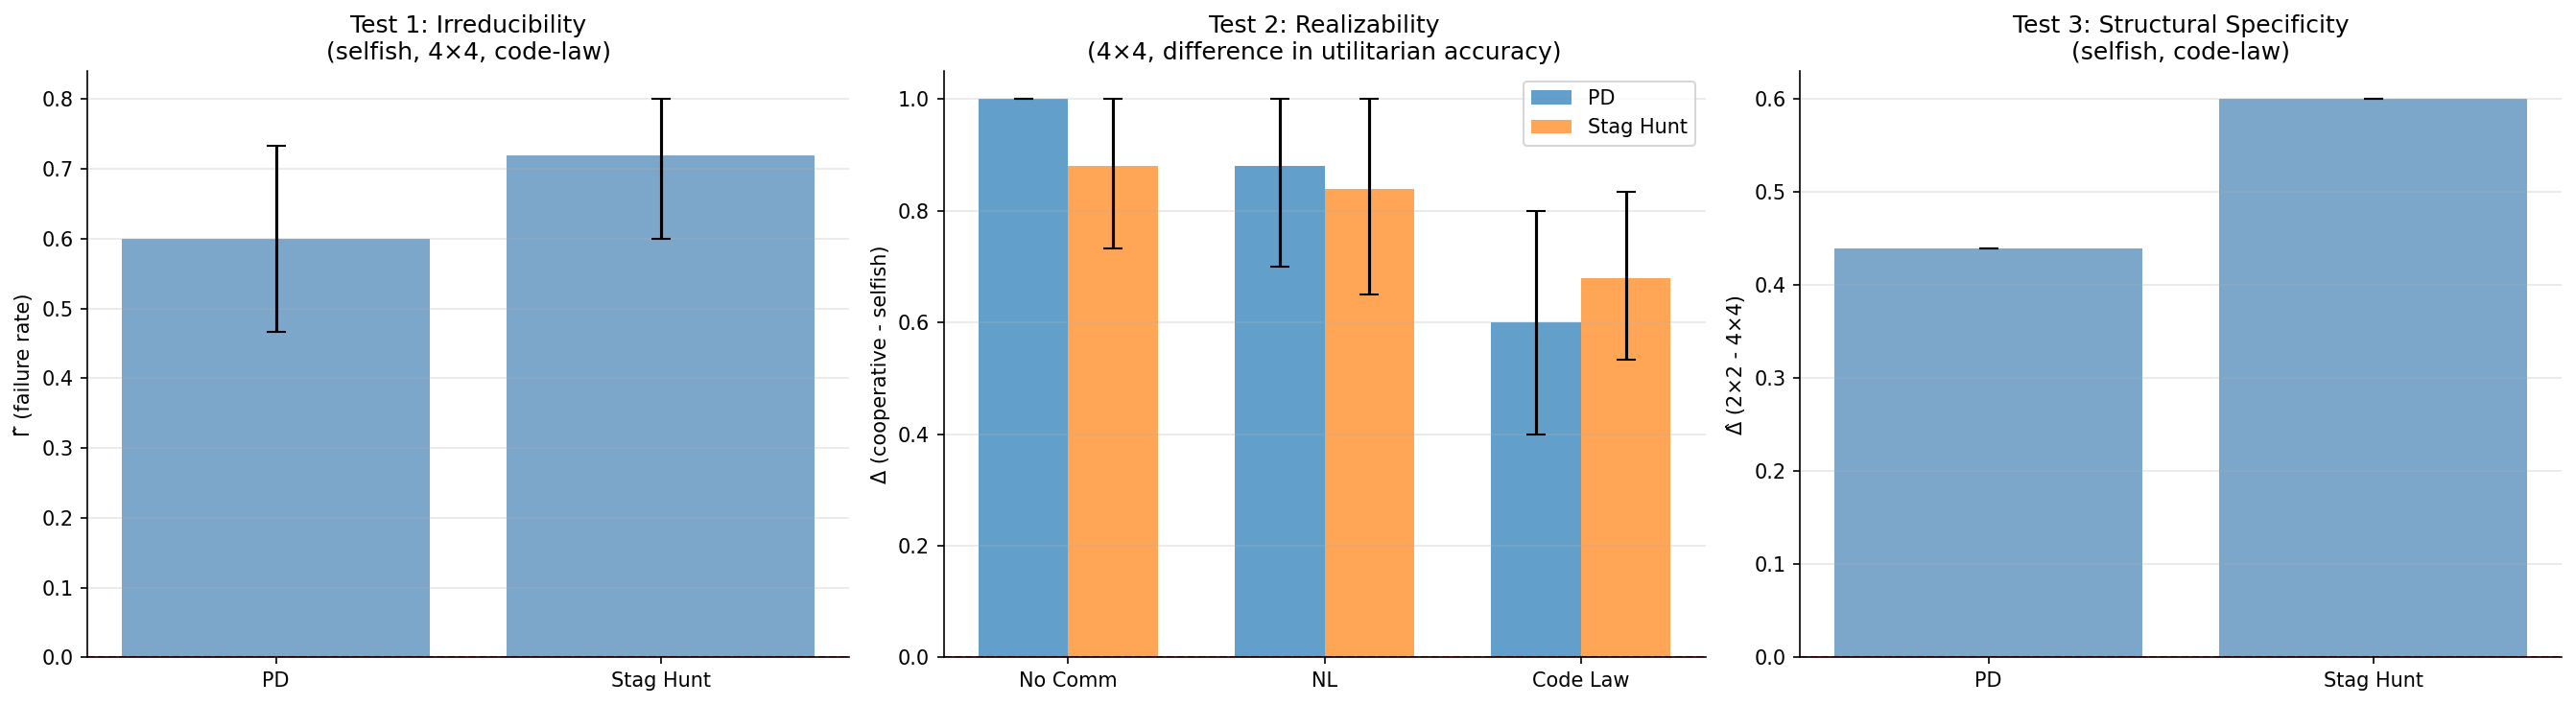

Saved: /home/charlie/code/research/gt-harmbench/results/figures/rq1_summary.png


In [33]:
# Cell 5.7: Visualization (Optional)

# Create summary plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Irreducibility
ax = axes[0]
for i, game in enumerate(['pd', 'sh']):
    game_data = irreducibility_df[
        (irreducibility_df['game'] == game) & 
        (irreducibility_df['cell'] == '(selfish, 4×4, code-law)')
    ].iloc[0]
    ax.bar(i, game_data['point_estimate'], 
           yerr=[[np.maximum(0, game_data['point_estimate'] - game_data['ci_lower'])], 
                 [np.maximum(0, game_data['ci_upper'] - game_data['point_estimate'])]],
           color='steelblue', alpha=0.7, capsize=5)
ax.set_xticks([0, 1])
ax.set_xticklabels(['PD', 'Stag Hunt'])
ax.set_ylabel('Γ̂ (failure rate)')
ax.set_title('Test 1: Irreducibility\n(selfish, 4×4, code-law)')
ax.axhline(y=0, color='red', linestyle='--', linewidth=1)
ax.grid(axis='y', alpha=0.3)

# Plot 2: Realizability differences
ax = axes[1]
x = np.arange(3)
width = 0.35
for i, game in enumerate(['pd', 'sh']):
    game_data = realizability_df[
        (realizability_df['game'] == game) & 
        (realizability_df['dataset_size'] == '4x4')
    ]
    if not game_data.empty:
        offsets = game_data['difference'].values
        # Clip so yerr is never negative (can happen if CI and point disagree slightly)
        errors_lower = np.maximum(0, offsets - game_data['ci_lower'].values)
        errors_upper = np.maximum(0, game_data['ci_upper'].values - offsets)
        ax.bar(x + i*width, offsets, width, yerr=[errors_lower, errors_upper],
               label=game.upper() if game == 'pd' else 'Stag Hunt',
               alpha=0.7, capsize=5)
ax.set_xticks(x + width/2)
ax.set_xticklabels(['No Comm', 'NL', 'Code Law'])
ax.set_ylabel('Δ (cooperative - selfish)')
ax.set_title('Test 2: Realizability\n(4×4, difference in utilitarian accuracy)')
ax.axhline(y=0, color='red', linestyle='--', linewidth=1)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Plot 3: Structural specificity
ax = axes[2]
for i, game in enumerate(['pd', 'sh']):
    game_data = specificity_df[specificity_df['game'] == game].iloc[0]
    ax.bar(i, game_data['point_estimate'],
           yerr=[[np.maximum(0, game_data['point_estimate'] - game_data['ci_lower'])], [0]],
           color='steelblue', alpha=0.7, capsize=5)
ax.set_xticks([0, 1])
ax.set_xticklabels(['PD', 'Stag Hunt'])
ax.set_ylabel('Δ̂ (2×2 - 4×4)')
ax.set_title('Test 3: Structural Specificity\n(selfish, code-law)')
ax.axhline(y=0, color='red', linestyle='--', linewidth=1)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
FIGURES_DIR.mkdir(exist_ok=True)
fig.savefig(FIGURES_DIR / "rq1_summary.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURES_DIR / 'rq1_summary.png'}")

In [34]:
# Cell 5.8: Per-Model Breakdown (Appendix)

print("\n" + "=" * 80)
print("APPENDIX: PER-MODEL BREAKDOWN")
print("=" * 80)

per_model_results = []

for model in sample_df['model_display'].unique():
    model_df = sample_df[sample_df['model_display'] == model]
    
    # Test 1: Irreducibility for this model
    for game in ['pd', 'sh']:
        try:
            result = test_irreducibility(
                model_df, game=game, dataset_size='4x4',
                prompt_mode='selfish', contract_mode='code_law',
                n_bootstrap=5000, seed=42
            )
            per_model_results.append({
                'model': model,
                'test': 'Irreducibility',
                'game': game,
                'estimate': result['point_estimate'],
                'ci_lower': result['ci_lower'],
                'p_value': result['p_value'],
            })
        except Exception as e:
            print(f"Error for {model} {game}: {e}")
            continue

per_model_df = pd.DataFrame(per_model_results)
print(per_model_df.to_string(index=False))

per_model_df.to_csv(RESULTS_DIR / "rq1_per_model.csv", index=False)
print(f"\nExported: {RESULTS_DIR / 'rq1_per_model.csv'}")


APPENDIX: PER-MODEL BREAKDOWN
        model           test game  estimate  ci_lower  p_value
 GPT-5.4 Mini Irreducibility   pd       0.6       0.6      0.0
 GPT-5.4 Mini Irreducibility   sh       0.8       0.8      0.0
       GPT-4o Irreducibility   pd       1.0       1.0      0.0
       GPT-4o Irreducibility   sh       1.0       1.0      0.0
Grok 4.1 Fast Irreducibility   pd       0.4       0.4      0.0
Grok 4.1 Fast Irreducibility   sh       0.6       0.6      0.0
  Gemma 4 31B Irreducibility   pd       0.4       0.4      0.0
  Gemma 4 31B Irreducibility   sh       0.6       0.6      0.0
      GPT-5.4 Irreducibility   pd       0.6       0.6      0.0
      GPT-5.4 Irreducibility   sh       0.6       0.6      0.0

Exported: /home/charlie/code/research/gt-harmbench/results/rq1_per_model.csv


## 6. RQ2: Are Contracting and Prosociality Complementary or Substitutive?

**Research Question**: Does the relationship between contract-based mechanism design and intrinsic agent prosociality depend on whether the environment is fully contractible?

From the paper: Contracting and prosociality are **substitutes when contractibility is full** (2×2) — contracts alone can close the cooperation gap. But they are **complements when incontractibility is introduced** (4×4) — contracts hit a structural floor that prosocial agents must close.

### Key Prediction: Three-way Interaction

The regime-dependence of the prosociality effect should differ between 2×2 and 4×4:

| variant | regime | selfish | cooperative | prosociality effect (Δ) |
|---|---|---|---|---|
| **2×2** | no-comm | < 1 | ≈ 1 | **large** |
| **2×2** | code-law | → 1 | ≈ 1 | **small** (substitutability) |
| **4×4** | no-comm | < 1 | ≈ 1 | **large** |
| **4×4** | code-law | < 1 | ≈ 1 | **large** (complementarity) |

### Three Statistical Tests

1. **Substitutability in 2×2**: Does the prosociality effect shrink as contracts get stronger?
2. **Persistence in 4×4**: Does the prosociality effect persist across regimes, including code-law?
3. **Three-way interaction** (headline): Is the regime-dependence different in 2×2 vs 4×4?

**Multiple Testing**: Holm-Bonferroni correction on 6 headline tests (α = 0.005 for Tests 2 and 3)

In [35]:
# Cell 6.1: Imports and Setup

# Import RQ2 analysis module
import sys
from pathlib import Path

# Add eval/analysis to path if needed
sys.path.insert(0, str(PROJECT_ROOT / "eval" / "analysis"))

from rq2_analysis import (
    test_substitutability_2x2,
    test_persistence_4x4,
    test_three_way_interaction,
    generate_rq2_summary_table,
)

print("RQ2 analysis module loaded")

# Reuse sample_df from Section 6 (already expanded)
print(f"Using existing sample_df with {len(sample_df)} records")

RQ2 analysis module loaded
Using existing sample_df with 900 records


In [47]:
# Cell 6.2: Data Preparation

# If running standalone, uncomment:
# from rq1_analysis import expand_to_sample_level
# rng = np.random.default_rng(42)
# sample_df = expand_to_sample_level(scenario_stats_df, rng=rng)

print(f"Sample data structure:")
print(sample_df[['game', 'dataset_size', 'prompt_mode', 'contract_mode', 'util_correct']].head(10))

# Verify cell counts for RQ2 (selfish and cooperative only)
print("\nCell counts for RQ2 (selfish/cooperative only):")
cell_counts = sample_df[
    sample_df['prompt_mode'].isin(['selfish', 'cooperative'])
].groupby(
    ['game', 'dataset_size', 'prompt_mode', 'contract_mode']
).size().reset_index(name='n_samples')
print(cell_counts)

Sample data structure:
  game dataset_size prompt_mode contract_mode  util_correct
0   pd          4x4        base       no_comm             0
1   pd          4x4        base       no_comm             0
2   pd          4x4        base       no_comm             0
3   pd          4x4        base       no_comm             0
4   pd          4x4        base       no_comm             0
5   pd          4x4        base       code_nl             1
6   pd          4x4        base       code_nl             1
7   pd          4x4        base       code_nl             1
8   pd          4x4        base       code_nl             1
9   pd          4x4        base       code_nl             1

Cell counts for RQ2 (selfish/cooperative only):
   game dataset_size  prompt_mode contract_mode  n_samples
0    pd          2x2  cooperative      code_law         25
1    pd          2x2  cooperative       code_nl         25
2    pd          2x2  cooperative       no_comm         25
3    pd          2x2      selfis

In [37]:
# Cell 6:3: Test 1 - Substitutability in 2×2

print("=" * 80)
print("TEST 1: SUBSTITUTABILITY IN 2×2")
print("=" * 80)
print("Testing if prosociality effect shrinks as contracts get stronger in 2×2")
print("Quantity: Δ(2×2, no-comm) - Δ(2×2, code-law) — should be positive\n")

substitutability_results = []

for game in ['pd', 'sh']:
    print(f"\n{'='*60}")
    print(f"Game: {game.upper() if game == 'pd' else 'Stag Hunt'}")
    print(f"{'='*60}")
    
    try:
        result = test_substitutability_2x2(
            sample_df,
            game=game,
            n_bootstrap=10000,
            seed=42,
        )
        
        print(f"\nProsociality × regime interaction p-value: {result['interaction_p']:.4e}")
        print(f"\nMarginal prosociality effects (Δ):")
        print(f"  No-comm:     {result['contrast_no_comm']:.4f}")
        print(f"  Code-law:    {result['contrast_code_law']:.4f}")
        print(f"  Difference:  {result['contrast_diff']:.4f}")
        print(f"  95% CI: [{result['ci_lower']:.4f}, {result['ci_upper']:.4f}]")
        
        print(f"\nSelfish + code-law accuracy: {result['selfish_code_law_acc']:.4f}")
        if result['has_ceiling_effect']:
            print("  → CEILING EFFECT: Contracts alone close the gap in 2×2")
            print("  This confirms substitutability in its strongest form")
        
        substitutability_results.append({
            'game': game,
            **result
        })
    except Exception as e:
        print(f"Error: {e}")
        continue

substitutability_df = pd.DataFrame(substitutability_results)

TEST 1: SUBSTITUTABILITY IN 2×2
Testing if prosociality effect shrinks as contracts get stronger in 2×2
Quantity: Δ(2×2, no-comm) - Δ(2×2, code-law) — should be positive


Game: PD


/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)



Prosociality × regime interaction p-value: 0.0000e+00

Marginal prosociality effects (Δ):
  No-comm:     1.0000
  Code-law:    0.1600
  Difference:  0.8400
  95% CI: [0.6000, 1.0000]

Selfish + code-law accuracy: 0.8400

Game: Stag Hunt

Prosociality × regime interaction p-value: 2.0141e-06

Marginal prosociality effects (Δ):
  No-comm:     0.6400
  Code-law:    0.0800
  Difference:  0.5600
  95% CI: [0.1500, 0.8667]

Selfish + code-law accuracy: 0.8800


In [38]:
# Cell 6.4: Test 2 - Persistence in 4×4

print("\n" + "=" * 80)
print("TEST 2: PERSISTENCE IN 4×4")
print("=" * 80)
print("Testing if prosociality effect persists across regimes in 4×4")
print("Key comparison: Δ(4×4, code-law) > 0\n")

persistence_results = []

for game in ['pd', 'sh']:
    print(f"\n{'='*60}")
    print(f"Game: {game.upper() if game == 'pd' else 'Stag Hunt'}")
    print(f"{'='*60}")
    
    try:
        result = test_persistence_4x4(
            sample_df,
            game=game,
            n_bootstrap=10000,
            seed=42,
        )
        
        print(f"\nProsociality effects (Δ) by regime:")
        for regime_val in ['no_comm', 'code_nl', 'code_law']:
            delta = result['delta_by_regime'][regime_val]['delta']
            ci_lower = result[f'ci_lower_{regime_val}']
            ci_upper = result[f'ci_upper_{regime_val}']
            p_val = result[f'p_{regime_val}']
            
            print(f"  {regime_val}: Δ = {delta:.4f}, 95% CI [{ci_lower:.4f}, {ci_upper:.4f}], p = {p_val:.4e}")
        
        print(f"\nHEADLINE: Δ(4×4, code-law) = {result['delta_code_law']:.4f}")
        print(f"  95% CI: [{result['ci_lower_code_law']:.4f}, {result['ci_upper_code_law']:.4f}]")
        print(f"  One-sided p: {result['p_code_law']:.4e}")
        
        if result['p_code_law'] < 0.005:
            print("  → PROSOCIALITY PERSISTS: Even under code-law in 4×4")
        
        print(f"\nInvariance test (Δ no-comm vs Δ code-law):")
        print(f"  Contrast: {result['invariance_contrast']:.4f}")
        print(f"  95% CI: [{result['invariance_ci_lower']:.4f}, {result['invariance_ci_upper']:.4f}]")
        print(f"  If CI includes 0, prosociality effect is invariant across regimes → COMPLEMENTARITY")
        
        persistence_results.append({
            'game': game,
            **result
        })
    except Exception as e:
        print(f"Error: {e}")
        continue

persistence_df = pd.DataFrame(persistence_results)


TEST 2: PERSISTENCE IN 4×4
Testing if prosociality effect persists across regimes in 4×4
Key comparison: Δ(4×4, code-law) > 0


Game: PD

Prosociality effects (Δ) by regime:
  no_comm: Δ = 1.0000, 95% CI [1.0000, 1.0000], p = 0.0000e+00
  code_nl: Δ = 0.8800, 95% CI [0.7000, 1.0000], p = 0.0000e+00
  code_law: Δ = 0.6000, 95% CI [0.4000, 0.8000], p = 0.0000e+00

HEADLINE: Δ(4×4, code-law) = 0.6000
  95% CI: [0.4000, 0.8000]
  One-sided p: 0.0000e+00
  → PROSOCIALITY PERSISTS: Even under code-law in 4×4

Invariance test (Δ no-comm vs Δ code-law):
  Contrast: 0.4000
  95% CI: [0.4000, 0.4000]
  If CI includes 0, prosociality effect is invariant across regimes → COMPLEMENTARITY

Game: Stag Hunt

Prosociality effects (Δ) by regime:
  no_comm: Δ = 0.8800, 95% CI [0.7333, 1.0000], p = 0.0000e+00
  code_nl: Δ = 0.8400, 95% CI [0.6600, 1.0000], p = 0.0000e+00
  code_law: Δ = 0.6800, 95% CI [0.5333, 0.8333], p = 0.0000e+00

HEADLINE: Δ(4×4, code-law) = 0.6800
  95% CI: [0.5333, 0.8333]
  One-s

In [39]:
# Cell 6.5: Test 3 - Three-way Interaction (HEADLINE)

print("\n" + "=" * 80)
print("TEST 3: THREE-WAY INTERACTION (HEADLINE)")
print("=" * 80)
print("Testing if regime-dependence of prosociality effect differs between 2×2 and 4×4")
print("Quantity: [Δ(2×2, no-comm) - Δ(2×2, code-law)] - [Δ(4×4, no-comm) - Δ(4×4, code-law)]\n")

three_way_results = []

for game in ['pd', 'sh']:
    print(f"\n{'='*60}")
    print(f"Game: {game.upper() if game == 'pd' else 'Stag Hunt'}")
    print(f"{'='*60}")
    
    try:
        result = test_three_way_interaction(
            sample_df,
            game=game,
            n_bootstrap=10000,
            seed=42,
        )
        
        print(f"\nLikelihood-ratio test (three-way interaction):")
        print(f"  p-value: {result['three_way_p']:.4e}")
        
        print(f"\nRegime-contrast by variant:")
        print(f"  2×2: Δ(no-comm) - Δ(code-law) = {result['contrast_2x2']:.4f}")
        print(f"  4×4: Δ(no-comm) - Δ(code-law) = {result['contrast_4x4']:.4f}")
        
        print(f"\nTHREE-WAY CONTRAST (headline):")
        print(f"  {result['contrast_2x2']:.4f} - {result['contrast_4x4']:.4f} = {result['three_way_contrast']:.4f}")
        print(f"  95% CI: [{result['ci_lower']:.4f}, {result['ci_upper']:.4f}]")
        print(f"  Bootstrap p: {result['p_value']:.4e}")
        
        if result['p_value'] < 0.005:
            print("  → SIGNIFICANT: Regime-dependence differs between 2×2 and 4×4")
            print("  This confirms COMPLEMENTARITY in 4×4 vs SUBSTITUTABILITY in 2×2")
        
        print(f"\nFull breakdown of prosociality effects:")
        for variant_val in ['2x2', '4x4']:
            print(f"  {variant_val}:")
            for regime_val in ['no_comm', 'code_nl', 'code_law']:
                delta = result['marginal_effects'][variant_val][regime_val]['delta']
                print(f"    {regime_val}: Δ = {delta:.4f}")
        
        three_way_results.append({
            'game': game,
            **result
        })
    except Exception as e:
        print(f"Error: {e}")
        import traceback
        traceback.print_exc()
        continue

three_way_df = pd.DataFrame(three_way_results)


TEST 3: THREE-WAY INTERACTION (HEADLINE)
Testing if regime-dependence of prosociality effect differs between 2×2 and 4×4
Quantity: [Δ(2×2, no-comm) - Δ(2×2, code-law)] - [Δ(4×4, no-comm) - Δ(4×4, code-law)]


Game: PD


/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-pack


Likelihood-ratio test (three-way interaction):
  p-value: 1.8028e-04

Regime-contrast by variant:
  2×2: Δ(no-comm) - Δ(code-law) = 0.8400
  4×4: Δ(no-comm) - Δ(code-law) = 0.4000

THREE-WAY CONTRAST (headline):
  0.8400 - 0.4000 = 0.4400
  95% CI: [-0.1500, 0.8000]
  Bootstrap p: 3.6300e-02

Full breakdown of prosociality effects:
  2x2:
    no_comm: Δ = 1.0000
    code_nl: Δ = 0.8800
    code_law: Δ = 0.1600
  4x4:
    no_comm: Δ = 1.0000
    code_nl: Δ = 0.8800
    code_law: Δ = 0.6000

Game: Stag Hunt

Likelihood-ratio test (three-way interaction):
  p-value: 2.0857e-02

Regime-contrast by variant:
  2×2: Δ(no-comm) - Δ(code-law) = 0.5600
  4×4: Δ(no-comm) - Δ(code-law) = 0.2000

THREE-WAY CONTRAST (headline):
  0.5600 - 0.2000 = 0.3600
  95% CI: [-0.1768, 0.8100]
  Bootstrap p: 6.7500e-02

Full breakdown of prosociality effects:
  2x2:
    no_comm: Δ = 0.6400
    code_nl: Δ = 0.2000
    code_law: Δ = 0.0800
  4x4:
    no_comm: Δ = 0.8800
    code_nl: Δ = 0.8400
    code_law: Δ = 

In [40]:
# Cell 6.6: Summary Table and Multiple Testing Correction

print("\n" + "=" * 80)
print("SUMMARY: ALL RQ2 TESTS")
print("=" * 80)

# Generate summary table
summary_df = generate_rq2_summary_table(sample_df, n_bootstrap=10000, seed=42)

# Format for display
display_df = summary_df.copy()
display_df['estimate_str'] = display_df.apply(
    lambda r: f"{r['estimate']:.4f} [{r['ci_lower']:.4f}, {r['ci_upper']:.4f}]"
    if pd.notna(r['ci_lower']) and pd.notna(r['ci_upper'])
    else f"{r['estimate']:.4f}",
    axis=1
)
display_df['sig'] = display_df['p_value'].apply(
    lambda p: "***" if pd.notna(p) and p < 0.001 else "**" if pd.notna(p) and p < 0.01 else "*" if pd.notna(p) and p < 0.05 else ""
)

print("\nHeadline tests (after Holm-Bonferroni correction, α = 0.005):")
headline_tests = display_df[display_df['headline_test'] == True][
    ['test', 'game', 'variant', 'estimate_str', 'p_value', 'sig', 'corrected_significant', 'note']
]
print(headline_tests.to_string(index=False))

# Export to CSV
RESULTS_DIR.mkdir(exist_ok=True)
summary_df.to_csv(RESULTS_DIR / "rq2_summary.csv", index=False)
print(f"\nExported: {RESULTS_DIR / 'rq2_summary.csv'}")


SUMMARY: ALL RQ2 TESTS


/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodel


Headline tests (after Holm-Bonferroni correction, α = 0.005):
                 test game variant             estimate_str  p_value sig corrected_significant             note
          Persistence   pd     4x4  0.6000 [0.4000, 0.8000]   0.0000 ***                  True                 
          Persistence   sh     4x4  0.6800 [0.5333, 0.8333]   0.0000 ***                  True                 
Three-way interaction   pd    both 0.4400 [-0.1500, 0.8000]   0.0363   *                 False LRT p=1.8028e-04
Three-way interaction   sh    both 0.3600 [-0.1768, 0.8100]   0.0675                     False LRT p=2.0857e-02

Exported: /home/charlie/code/research/gt-harmbench/results/rq2_summary.csv


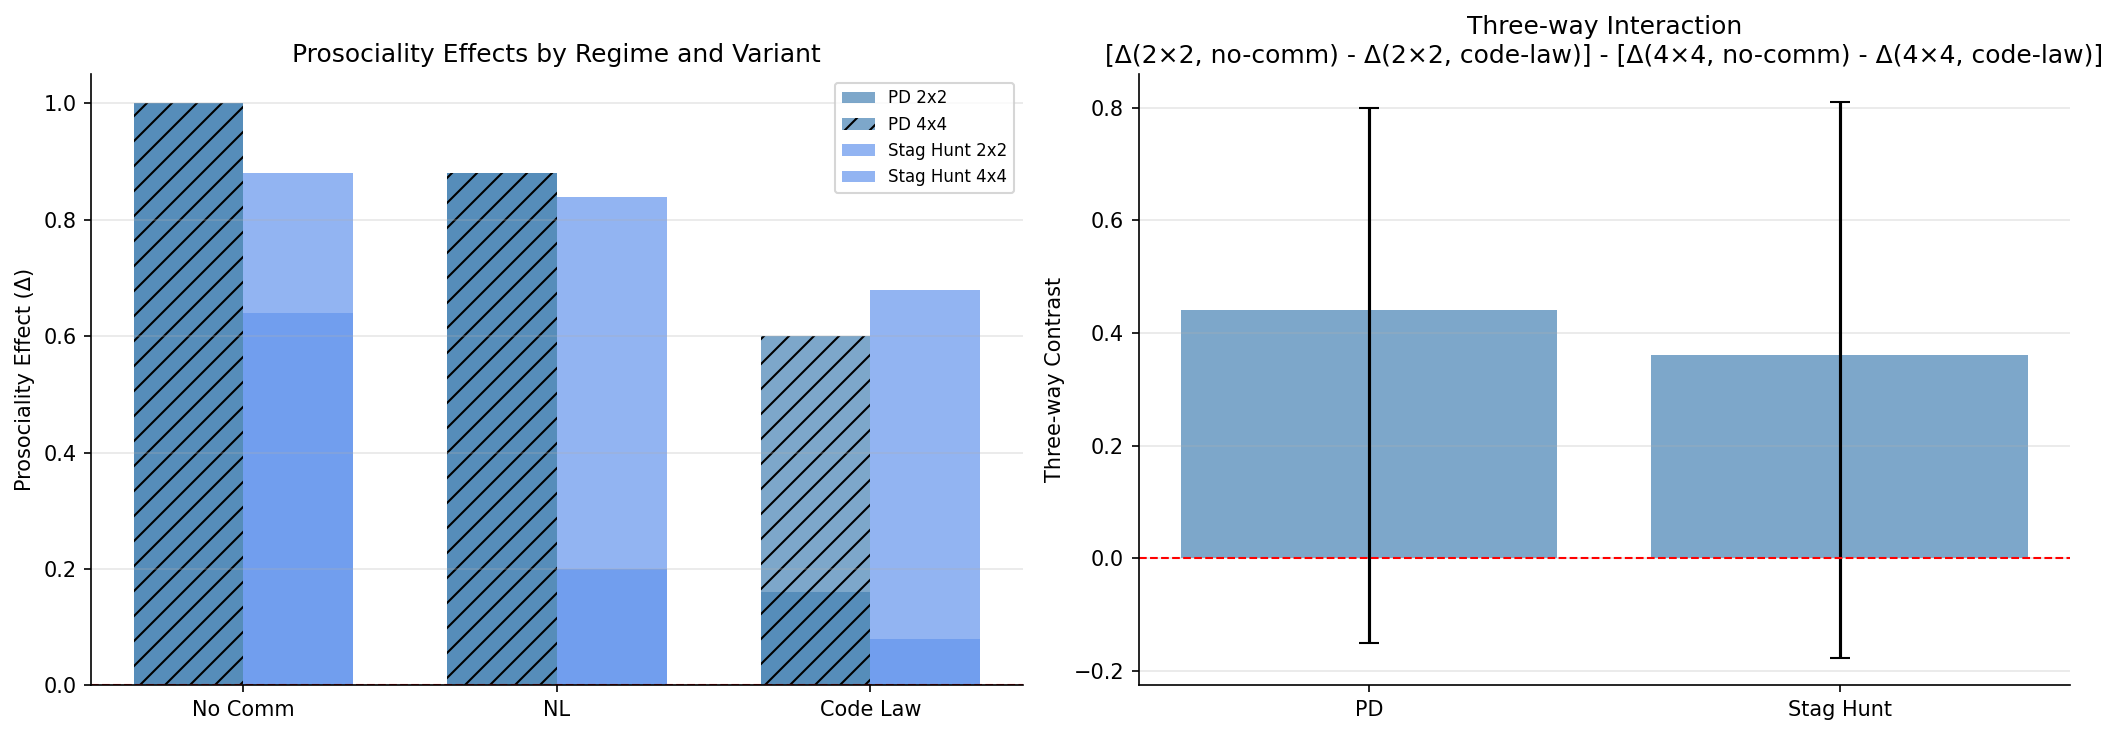

Saved: /home/charlie/code/research/gt-harmbench/results/figures/rq2_summary.png


In [41]:
# Cell 6.7: Visualization

# Create visualization of prosociality effects across regimes and variants
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Prosociality effects by regime and variant
ax = axes[0]
variants = ['2x2', '4x4']
regimes = ['no_comm', 'code_nl', 'code_law']
x = np.arange(len(regimes))
width = 0.35

for i, game in enumerate(['pd', 'sh']):
    game_data = three_way_results[i] if i < len(three_way_results) else None
    if game_data is None:
        continue
    
    effects_2x2 = [game_data['marginal_effects']['2x2'][r]['delta'] for r in regimes]
    effects_4x4 = [game_data['marginal_effects']['4x4'][r]['delta'] for r in regimes]
    
    offset = (i - 0.5) * width
    ax.bar(x + offset, effects_2x2, width, label=f'{game.upper() if game=="pd" else "Stag Hunt"} 2x2',
           alpha=0.7, color=['steelblue', 'cornflowerblue'][i])
    ax.bar(x + offset, effects_4x4, width, label=f'{game.upper() if game=="pd" else "Stag Hunt"} 4x4',
           alpha=0.7, hatch=['//', ''][i], color=['steelblue', 'cornflowerblue'][i])

ax.set_ylabel('Prosociality Effect (Δ)')
ax.set_title('Prosociality Effects by Regime and Variant')
ax.set_xticks(x)
ax.set_xticklabels(['No Comm', 'NL', 'Code Law'])
ax.axhline(y=0, color='red', linestyle='--', linewidth=1)
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# Plot 2: Three-way interaction
ax = axes[1]
games_list = ['PD', 'Stag Hunt']
if len(three_way_results) >= 2:
    three_way_contrasts = [r['three_way_contrast'] for r in three_way_results]
    cis_lower = [r['ci_lower'] for r in three_way_results]
    cis_upper = [r['ci_upper'] for r in three_way_results]
    
    x_pos = np.arange(len(games_list))
    ax.bar(x_pos, three_way_contrasts, yerr=[np.array(three_way_contrasts) - np.array(cis_lower),
                                               np.array(cis_upper) - np.array(three_way_contrasts)],
           color='steelblue', alpha=0.7, capsize=5)
    
    ax.set_ylabel('Three-way Contrast')
    ax.set_title('Three-way Interaction\n[Δ(2×2, no-comm) - Δ(2×2, code-law)] - [Δ(4×4, no-comm) - Δ(4×4, code-law)]')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(games_list)
    ax.axhline(y=0, color='red', linestyle='--', linewidth=1)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
FIGURES_DIR.mkdir(exist_ok=True)
fig.savefig(FIGURES_DIR / "rq2_summary.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURES_DIR / 'rq2_summary.png'}")

In [42]:
# Cell 6.8: Per-Model Breakdown (Appendix)

print("\n" + "=" * 80)
print("APPENDIX: PER-MODEL BREAKDOWN")
print("=" * 80)

per_model_results = []

for model in sample_df['model_display'].unique():
    model_df = sample_df[sample_df['model_display'] == model]
    
    # Test three-way interaction for this model
    for game in ['pd', 'sh']:
        try:
            result = test_three_way_interaction(
                model_df, game=game, n_bootstrap=5000, seed=42
            )
            per_model_results.append({
                'model': model,
                'game': game,
                'three_way_contrast': result['three_way_contrast'],
                'ci_lower': result['ci_lower'],
                'ci_upper': result['ci_upper'],
                'p_value': result['p_value'],
                'contrast_2x2': result['contrast_2x2'],
                'contrast_4x4': result['contrast_4x4'],
            })
        except Exception as e:
            print(f"Error for {model} {game}: {e}")
            continue

per_model_df = pd.DataFrame(per_model_results)

# Format for display
display_model_df = per_model_df.copy()
display_model_df['contrast_str'] = display_model_df.apply(
    lambda r: f"{r['three_way_contrast']:.4f} [{r['ci_lower']:.4f}, {r['ci_upper']:.4f}]",
    axis=1
)
print(display_model_df[['model', 'game', 'contrast_str', 'p_value', 'contrast_2x2', 'contrast_4x4']].to_string(index=False))

per_model_df.to_csv(RESULTS_DIR / "rq2_per_model.csv", index=False)
print(f"\nExported: {RESULTS_DIR / 'rq2_per_model.csv'}")


APPENDIX: PER-MODEL BREAKDOWN


/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
/home/charlie/miniconda3/envs/contracts/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The 

        model game             contrast_str  p_value  contrast_2x2  contrast_4x4
 GPT-5.4 Mini   pd 0.6000 [-1.0000, 1.6000]   0.5282           1.0           0.4
 GPT-5.4 Mini   sh 0.6000 [-1.0000, 1.6000]   0.5282           0.8           0.2
       GPT-4o   pd 0.2000 [-1.8000, 2.0000]   0.5282           0.2           0.0
       GPT-4o   sh 0.4000 [-1.2000, 1.6000]   0.5282           0.4           0.0
Grok 4.1 Fast   pd 0.4000 [-1.0000, 1.4000]   0.5282           1.0           0.6
Grok 4.1 Fast   sh 0.2000 [-1.0000, 1.2000]   0.5282           0.6           0.4
  Gemma 4 31B   pd 0.4000 [-1.0000, 1.4000]   0.5282           1.0           0.6
  Gemma 4 31B   sh 0.2000 [-0.6000, 0.8000]   0.5282           0.2           0.0
      GPT-5.4   pd 0.6000 [-1.0000, 1.6000]   0.5282           1.0           0.4
      GPT-5.4   sh 0.4000 [-1.0000, 1.4000]   0.5282           0.8           0.4

Exported: /home/charlie/code/research/gt-harmbench/results/rq2_per_model.csv
